# Sistem Deteksi Warna Bernuansa & Koreksi Buta Warna (CVD) Berbasis OpenCV

## Abstrak & Latar Belakang
Individu dengan *Color Vision Deficiency* (CVD)—baik *protanopia*, *deuteranopia*, maupun *tritanopia*—mengalami penyempitan persepsi spektrum warna sehingga pasangan warna tertentu yang tampak kontras bagi penglihatan normal menjadi sulit dibedakan atau melebur[cite: 2]. Notebook ini mengimplementasikan prototipe sistem visi komputer untuk[cite: 1, 2]:
1. **Identifikasi & Segmentasi Warna Bernuansa:** Mengklasifikasikan objek berwarna ke dalam 34 referensi nuansa warna (10 keluarga warna) menggunakan ruang warna perseptual **CIELAB** dan metrik jarak **CIEDE2000** ($\Delta E_{00}$)[cite: 1, 2].
2. **Simulasi & Koreksi CVD (*Daltonization*):** Mensimulasikan persepsi visual dikromat pada ruang RGB linear serta melakukan koreksi warna baik secara global maupun lokal berbasis deteksi perbatasan warna yang melebur[cite: 1, 2].
3. **Evaluasi Kuantitatif & Pemrosesan *Real-Time*:** Mengukur perubahan jarak persepsi $\Delta E_{00}$ sebelum dan sesudah koreksi, menguji ketahanan penamaan warna terhadap variasi pencahayaan, serta menjalankan deteksi objek dan kamera asisten CVD secara *real-time*[cite: 1, 2].

---

## Arsitektur Pipeline Deteksi Warna
1. **Akuisisi & Pra-pemrosesan:** Citra input (BGR) disesuaikan ukurannya (`fit_max_side`) dan dihaluskan menggunakan *median blur* untuk meredam *noise* frekuensi tinggi tanpa mengaburkan batas tepi warna[cite: 1, 2].
2. **Kuantisasi & Pemetaan Ruang Warna:** Piksel dikuantisasi menjadi 6-bit per kanal untuk memangkas kompleksitas komputasi, dikonversi ke ruang warna **CIELAB**, lalu dipetakan ke warna palet terdekat menggunakan jarak **CIEDE2000**[cite: 1, 2].
3. **Morfologi & Ekstraksi Komponen Terhubung:** Masker biner hasil segmentasi (*per-shade* atau *per-family*) dibersihkan menggunakan operasi morfologi *opening* dan *closing*, kemudian diekstraksi menjadi *bounding box* objek melalui `connectedComponentsWithStats`[cite: 1, 2].
4. **Agregasi Statistik:** Representasi warna akhir dari setiap objek dihitung menggunakan nilai **median** piksel di dalam komponen terhubung guna menghindari distorsi akibat *specular highlight* atau bayangan tepi[cite: 1, 2].

---

## Daftar Isi
1. [Konfigurasi Lingkungan & Pustaka](#1-konfigurasi-lingkungan--pustaka)
2. [Matematika Ruang Warna & Verifikasi CIEDE2000](#2-matematika-ruang-warna--verifikasi-ciede2000)
3. [Definisi Palet Warna Referensi](#3-definisi-palet-warna-referensi)
4. [Mesin Klasifikasi & Penamaan Warna](#4-mesin-klasifikasi--penamaan-warna)
5. [Pipeline Deteksi Objek & Inspeksi Titik](#5-pipeline-deteksi-objek--inspeksi-titik)
6. [Simulasi CVD & Algoritma Daltonization](#6-simulasi-cvd--algoritma-daltonization)
7. [Kerangka Evaluasi Kuantitatif & Benchmark](#7-kerangka-evaluasi-kuantitatif--benchmark)
8. [Eksperimen Citra Statis & Ekspor Batch](#8-eksperimen-citra-statis-dan-ekspor-batch)
9. [Deteksi Multi-Warna Real-Time (Webcam)](#9-deteksi-multi-warna-real-time-webcam)
10. [Kamera Asisten CVD & Koreksi Lokal Adaptif](#10-kamera-asisten-cvd--koreksi-lokal-adaptif)

## 1. Konfigurasi Lingkungan & Pustaka
Memuat pustaka standar serta dependensi komputasi numerik (`numpy`, `pandas`), pemrosesan citra (`opencv-python`), dan visualisasi (`matplotlib`)[cite: 1, 2].

In [28]:
import os
import glob
import time
from collections import namedtuple
from typing import Any, Dict, List, Optional, Tuple

import cv2
import numpy as np
import numpy.typing as npt
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

OpenCV : 5.0.0
NumPy  : 2.5.4


## 2. Matematika Ruang Warna & Verifikasi CIEDE2000

Jarak Euclidean pada ruang warna sRGB tidak seragam secara perseptual bagi mata manusia[cite: 2]. Oleh karena itu, seluruh pencocokan dan evaluasi warna dalam sistem ini dilakukan di ruang warna **CIELAB** ($L^*, a^*, b^*$) menggunakan formula standar **CIEDE2000** ($\Delta E_{00}$) yang mengoreksi ketidakseragaman persepsi pada kecerahan ($\Delta L'$), kroma ($\Delta C'$), dan rona ($\Delta H'$) beserta suku interaksi rotasi biru-ungu ($R_T$)[cite: 1, 2]:

$$\Delta E_{00} = \sqrt{\left(\frac{\Delta L'}{k_L S_L}\right)^2 + \left(\frac{\Delta C'}{k_C S_C}\right)^2 + \left(\frac{\Delta H'}{k_H S_H}\right)^2 + R_T \left(\frac{\Delta C'}{k_C S_C}\right) \left(\frac{\Delta H'}{k_H S_H}\right)}$$

dengan faktor bobot parametrik $k_L = k_C = k_H = 1$. Pedoman interpretasi nilai $\Delta E_{00}$:
* $\Delta E_{00} < 1,0$: Perbedaan warna tidak terdeteksi oleh mata manusia.
* $1,0 \le \Delta E_{00} < 2,0$: Perbedaan sangat halus (hanya terlihat pada pengamatan berdampingan).
* $2,0 \le \Delta E_{00} < 10,0$: Perbedaan warna terlihat jelas saat dibandingkan.
* $\Delta E_{00} \ge 50,0$: Dua kategori warna yang berbeda secara kontras.

In [29]:
def rgb_to_lab(rgb: npt.ArrayLike) -> npt.NDArray[np.float64]:
    """Mengonversi array warna sRGB (rentang 0-255, D65) ke ruang warna CIELAB (L: 0-100, a/b: ±128)."""
    arr = np.asarray(rgb, dtype=np.float32)
    shp = arr.shape
    lab = cv2.cvtColor(arr.reshape(-1, 1, 3) / 255.0, cv2.COLOR_RGB2LAB)
    return lab.reshape(shp).astype(np.float64)


def lab_to_rgb(lab: npt.ArrayLike) -> npt.NDArray[np.float64]:
    """Mengonversi array warna CIELAB kembali ke ruang warna sRGB (rentang 0-255, float)."""
    arr = np.asarray(lab, dtype=np.float32)
    shp = arr.shape
    rgb = cv2.cvtColor(arr.reshape(-1, 1, 3), cv2.COLOR_LAB2RGB)
    return np.clip(rgb.reshape(shp) * 255.0, 0, 255)


def ciede2000(lab1: npt.ArrayLike, lab2: npt.ArrayLike) -> npt.NDArray[np.float64]:
    """Menghitung jarak persepsi warna CIEDE2000 (ΔE00) secara tervektorisasi dengan dukungan broadcasting.

    Args:
        lab1: Array koordinat warna pertama dalam ruang CIELAB (..., 3).
        lab2: Array koordinat warna kedua dalam ruang CIELAB (..., 3).

    Returns:
        Array jarak warna ΔE00 (semakin kecil nilai menunjukkan kemiripan perseptual yang semakin tinggi).
    """
    lab1 = np.asarray(lab1, dtype=np.float64)
    lab2 = np.asarray(lab2, dtype=np.float64)
    L1, a1, b1 = lab1[..., 0], lab1[..., 1], lab1[..., 2]
    L2, a2, b2 = lab2[..., 0], lab2[..., 1], lab2[..., 2]

    C1, C2 = np.hypot(a1, b1), np.hypot(a2, b2)
    Cbar = (C1 + C2) / 2.0
    G = 0.5 * (1.0 - np.sqrt(Cbar ** 7 / (Cbar ** 7 + 25.0 ** 7)))
    a1p, a2p = (1 + G) * a1, (1 + G) * a2
    C1p, C2p = np.hypot(a1p, b1), np.hypot(a2p, b2)
    h1p = np.degrees(np.arctan2(b1, a1p)) % 360.0
    h2p = np.degrees(np.arctan2(b2, a2p)) % 360.0

    dLp = L2 - L1
    dCp = C2p - C1p
    dhp = h2p - h1p
    dhp = np.where(dhp > 180, dhp - 360, dhp)
    dhp = np.where(dhp < -180, dhp + 360, dhp)
    prodC = C1p * C2p
    dhp = np.where(prodC == 0, 0.0, dhp)
    dHp = 2.0 * np.sqrt(prodC) * np.sin(np.radians(dhp / 2.0))

    Lbar = (L1 + L2) / 2.0
    Cbarp = (C1p + C2p) / 2.0
    hsum = h1p + h2p
    hbar = np.where(np.abs(h1p - h2p) <= 180, hsum / 2.0,
                    np.where(hsum < 360, (hsum + 360) / 2.0, (hsum - 360) / 2.0))
    hbar = np.where(prodC == 0, hsum, hbar)

    T = (1 - 0.17 * np.cos(np.radians(hbar - 30)) + 0.24 * np.cos(np.radians(2 * hbar))
         + 0.32 * np.cos(np.radians(3 * hbar + 6)) - 0.20 * np.cos(np.radians(4 * hbar - 63)))
    dtheta = 30.0 * np.exp(-(((hbar - 275) / 25.0) ** 2))
    Rc = 2.0 * np.sqrt(Cbarp ** 7 / (Cbarp ** 7 + 25.0 ** 7))
    Sl = 1 + 0.015 * (Lbar - 50) ** 2 / np.sqrt(20 + (Lbar - 50) ** 2)
    Sc = 1 + 0.045 * Cbarp
    Sh = 1 + 0.015 * Cbarp * T
    Rt = -np.sin(np.radians(2 * dtheta)) * Rc

    return np.sqrt((dLp / Sl) ** 2 + (dCp / Sc) ** 2 + (dHp / Sh) ** 2
                   + Rt * (dCp / Sc) * (dHp / Sh))


def rgb_to_hsv_deg(rgb: npt.ArrayLike) -> Tuple[float, float, float]:
    """Mengonversi satu piksel RGB (0-255) ke tuple HSV (Hue: 0-360°, Saturation: 0-100%, Value: 0-100%)."""
    px = np.uint8(np.clip(np.round(rgb), 0, 255)).reshape(1, 1, 3)
    h, s, v = cv2.cvtColor(px, cv2.COLOR_RGB2HSV)[0, 0]
    return float(h) * 2.0, float(s) / 255.0 * 100.0, float(v) / 255.0 * 100.0


def verify_ciede2000() -> None:
    """Memverifikasi akurasi numerik fungsi ciede2000 terhadap dataset referensi Sharma, Wu, & Dalal (2005)."""
    ref = [((50.0, 2.6772, -79.7751), (50.0, 0.0, -82.7485), 2.0425),
            ((50.0, 3.1571, -77.2803), (50.0, 0.0, -82.7485), 2.8615),
            ((50.0, 0.0, 0.0), (50.0, -1.0, 2.0), 2.3669),
            ((50.0, 2.49, -0.001), (50.0, -2.49, 0.0009), 7.1792),
            ((60.2574, -34.0099, 36.2677), (60.4626, -34.1751, 39.4387), 1.2644)]
    for a, b, expected in ref:
        got = float(ciede2000(a, b))
        assert abs(got - expected) < 1e-3, f"CIEDE2000 salah: {got} != {expected}"
    print("CIEDE2000 terverifikasi terhadap", len(ref), "data uji referensi.")


verify_ciede2000()

CIEDE2000 terverifikasi terhadap 5 data uji referensi.


## 3. Definisi Palet Warna Referensi
Palet referensi (`PALETTE`) dirancang mencakup **34 titik warna bernuansa** yang dikelompokkan ke dalam **10 keluarga warna utama** (*Merah, Pink, Oranye, Coklat, Kuning, Hijau, Tosca, Biru, Ungu, Netral*)[cite: 1, 2]. Pengelompokan dua tingkat ini (*shade* vs *family*) memungkinkan sistem melakukan segmentasi objek secara fleksibel: memisahkan setiap gradasi warna secara spesifik atau menggabungkan area berbayang pada satu objek yang sama ke dalam satu keluarga warna[cite: 1, 2].

In [30]:
ColorDef = namedtuple("ColorDef", "name family rgb")

PALETTE = [
    # --- Merah
    ColorDef("Merah Marun",        "Merah",  (110, 10, 25)),
    ColorDef("Merah Tua",          "Merah",  (160, 0, 0)),
    ColorDef("Merah",              "Merah",  (230, 25, 25)),
    # --- Pink (merah muda)
    ColorDef("Pink Tua",           "Pink",   (225, 40, 130)),
    ColorDef("Merah Muda (Pink)",  "Pink",   (255, 150, 175)),
    ColorDef("Pink Pastel",        "Pink",   (255, 215, 225)),
    # --- Oranye
    ColorDef("Oranye Tua",         "Oranye", (200, 90, 10)),
    ColorDef("Oranye",             "Oranye", (255, 140, 0)),
    ColorDef("Oranye Muda",        "Oranye", (255, 195, 140)),
    # --- Coklat / krem
    ColorDef("Coklat Tua",         "Coklat", (75, 45, 25)),
    ColorDef("Coklat",             "Coklat", (140, 85, 45)),
    ColorDef("Coklat Muda",        "Coklat", (200, 160, 115)),
    ColorDef("Krem",               "Coklat", (240, 225, 195)),
    # --- Kuning
    ColorDef("Kuning Tua",         "Kuning", (195, 155, 0)),
    ColorDef("Kuning",             "Kuning", (255, 225, 0)),
    ColorDef("Kuning Muda",        "Kuning", (255, 245, 160)),
    # --- Hijau
    ColorDef("Hijau Tua",          "Hijau",  (0, 85, 35)),
    ColorDef("Hijau Lumut",        "Hijau",  (105, 115, 30)),
    ColorDef("Hijau",              "Hijau",  (35, 170, 65)),
    ColorDef("Hijau Muda",         "Hijau",  (160, 235, 140)),
    # --- Tosca / cyan
    ColorDef("Tosca",              "Tosca",  (0, 150, 140)),
    ColorDef("Cyan",               "Tosca",  (0, 225, 235)),
    # --- Biru
    ColorDef("Biru Navy",          "Biru",   (0, 0, 110)),
    ColorDef("Biru Tua",           "Biru",   (25, 55, 160)),
    ColorDef("Biru",               "Biru",   (35, 100, 235)),
    ColorDef("Biru Muda",          "Biru",   (140, 200, 250)),
    # --- Ungu
    ColorDef("Ungu Tua",           "Ungu",   (65, 10, 100)),
    ColorDef("Ungu",               "Ungu",   (135, 55, 175)),
    ColorDef("Ungu Muda",          "Ungu",   (200, 170, 230)),
    # --- Netral
    ColorDef("Hitam",              "Netral", (20, 20, 20)),
    ColorDef("Abu-abu Tua",        "Netral", (80, 80, 80)),
    ColorDef("Abu-abu",            "Netral", (135, 135, 135)),
    ColorDef("Abu-abu Muda",       "Netral", (200, 200, 200)),
    ColorDef("Putih",              "Netral", (245, 245, 245)),
]

PALETTE_NAMES = [c.name for c in PALETTE]
assert len(set(PALETTE_NAMES)) == len(PALETTE_NAMES), "Nama warna di PALETTE harus unik"
PALETTE_RGB = np.array([c.rgb for c in PALETTE], dtype=np.float64)
PALETTE_LAB = rgb_to_lab(PALETTE_RGB)
FAMILIES = list(dict.fromkeys(c.family for c in PALETTE))
FAMILY_ID = np.array([FAMILIES.index(c.family) for c in PALETTE], dtype=np.uint8)


def get_rgb(name: str) -> npt.NDArray[np.float64]:
    """Mengambil nilai array RGB (float64) dari palet referensi berdasarkan nama warna (case-insensitive)."""
    for c in PALETTE:
        if c.name.lower() == name.lower():
            return np.array(c.rgb, dtype=np.float64)
    raise KeyError(f"Warna '{name}' tidak ada di PALETTE")


def show_palette(cols: int = 6) -> None:
    """Memvisualisasikan seluruh warna dalam palet referensi beserta label nama dan koordinat RGB-nya."""
    rows = int(np.ceil(len(PALETTE) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 1.7 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, c in zip(axes.ravel(), PALETTE):
        ax.imshow(np.full((10, 10, 3), c.rgb, dtype=np.uint8))
        ax.set_title(f"{c.name}\n{c.rgb}", fontsize=8)
    fig.suptitle("Palet warna referensi", fontsize=12)
    plt.tight_layout()
    plt.show()

## 4. Mesin Klasifikasi & Penamaan Warna
Untuk menjaga efisiensi komputasi pada citra beresolusi tinggi, fungsi `classify_pixels` menerapkan **kuantisasi warna 6-bit per kanal** ($\lfloor \text{RGB} / 4 \rfloor \times 4 + 2$) sebelum melakukan pencarian warna unik (`np.unique`)[cite: 1, 2]. Pendekatan ini mereduksi jumlah evaluasi jarak matriks CIEDE2000 secara signifikan dari ratusan ribu piksel menjadi hanya beberapa ratus/ribu warna unik per *frame*[cite: 1, 2].

Pada tingkat identifikasi objek (`identify_color`), suatu warna ditandai memiliki nuansa **ambigu** apabila selisih jarak perseptual antara kandidat palet terdekat pertama ($d_1$) dan kedua ($d_2$) memenuhi kriteria[cite: 1, 2]:

$$\Delta E_{00}^{(2)} - \Delta E_{00}^{(1)} < 2,0$$

In [31]:
def nearest_palette(lab: npt.ArrayLike, chunk: int = 4000) -> Tuple[npt.NDArray[np.int32], npt.NDArray[np.float64]]:
    """Mencari indeks warna palet referensi terdekat dan jarak ΔE00 minimum secara bertahap (chunked).

    Args:
        lab: Array koordinat CIELAB berukuran (N, 3).
        chunk: Ukuran batch evaluasi untuk membatasi alokasi memori matriks jarak.

    Returns:
        Tuple berisi (array indeks palet terdekat (N,), array jarak ΔE00 minimum (N,)).
    """
    lab = np.asarray(lab, dtype=np.float64).reshape(-1, 3)
    idx = np.empty(len(lab), dtype=np.int32)
    dist = np.empty(len(lab), dtype=np.float64)
    for s in range(0, len(lab), chunk):
        d = ciede2000(lab[s:s + chunk, None, :], PALETTE_LAB[None, :, :])
        idx[s:s + chunk] = d.argmin(axis=1)
        dist[s:s + chunk] = d.min(axis=1)
    return idx, dist


def identify_color(rgb: npt.ArrayLike) -> Dict[str, Any]:
    """Mengidentifikasi nama warna, keluarga, koordinat ruang warna (RGB, HEX, HSV, Lab), dan status ambiguitas."""    
    rgb = np.clip(np.round(np.asarray(rgb, dtype=np.float64)), 0, 255)
    lab = rgb_to_lab(rgb.reshape(1, 3))[0]
    d = ciede2000(lab[None, :], PALETTE_LAB)
    order = np.argsort(d)
    i = int(order[0])
    r, g, b = (int(v) for v in rgb)
    h, s, v = rgb_to_hsv_deg(rgb)
    top = [(PALETTE[int(j)].name, round(float(d[j]), 1)) for j in order[:3]]
    # tandai ambigu jika kandidat ke-2 hampir sama dekatnya
    ambigu = (d[order[1]] - d[order[0]]) < 2.0
    return {
        "name": PALETTE[i].name, "family": PALETTE[i].family,
        "R": r, "G": g, "B": b, "HEX": f"#{r:02X}{g:02X}{b:02X}",
        "H": round(h, 1), "S": round(s, 1), "V": round(v, 1),
        "L": round(float(lab[0]), 1), "a": round(float(lab[1]), 1), "b": round(float(lab[2]), 1),
        "delta_e": round(float(d[i]), 1), "top3": top, "ambigu": bool(ambigu),
        "mirip": top[1][0] if ambigu else None,
    }


def classify_pixels(rgb: npt.NDArray[np.uint8]) -> npt.NDArray[np.uint8]:
    """Memetakan setiap piksel citra RGB ke indeks warna palet terdekat melalui kuantisasi 6-bit dan deduplikasi."""   
    h, w = rgb.shape[:2]
    q = np.clip((rgb.astype(np.int32) // 4) * 4 + 2, 0, 255)          # Kuantisasi 6-bit/kanal untuk membatasi jumlah kombinasi RGB unik sebelum evaluasi CIEDE2000
    key = ((q[..., 0] << 16) | (q[..., 1] << 8) | q[..., 2]).ravel()
    uniq, inv = np.unique(key, return_inverse=True)
    ur = np.stack([(uniq >> 16) & 255, (uniq >> 8) & 255, uniq & 255], axis=1).astype(np.uint8)
    idx, _ = nearest_palette(rgb_to_lab(ur))
    return idx[inv.ravel()].reshape(h, w).astype(np.uint8)

## 5. Pipeline Deteksi Objek, Inspeksi Titik, & Warna Dominan

Tahap lokalisasi objek berwarna (`detect_colors`) menggabungkan pemetaan palet piksel dengan operasi morfologi matematis menggunakan elemen penstruktur elips ($E_k$ berukuran `morph_ksize` $\times$ `morph_ksize`):
1. **Morphological Opening ($M \circ E_k$):** Mengeliminasi derau titik (*salt noise*) atau artefak piksel terisolasi.
2. **Morphological Closing ($M \bullet E_k$):** Menutup celah sempit atau lubang internal di dalam area objek yang homogen.
3. **Connected Components Labeling (8-Connectivity):** Mengekstraksi *bounding box* setiap komponen terhubung yang memenuhi batas fraksi luas minimum (`min_area_ratio`) dan maksimum (`max_area_ratio`).

Untuk analisis distribusi warna global tanpa bergantung pada batas-batas palet, fungsi `dominant_colors` menerapkan pengelompokan **K-Means Clustering** ($k$ klaster, inisialisasi *K-Means++*) secara langsung pada ruang warna **CIELAB** setelah citra diperkecil ke sisi maksimum 200 piksel.

In [32]:
FONT = cv2.FONT_HERSHEY_SIMPLEX


def fit_max_side(img_bgr: npt.NDArray[np.uint8], max_side: int = 1000) -> npt.NDArray[np.uint8]:
    """Menyesuaikan resolusi citra BGR secara proporsional apabila sisi terpanjang melebihi max_side."""
    h, w = img_bgr.shape[:2]
    if max(h, w) <= max_side:
        return img_bgr
    sc = max_side / max(h, w)
    return cv2.resize(img_bgr, (int(w * sc), int(h * sc)), interpolation=cv2.INTER_AREA)


def _draw_detections(img_bgr: npt.NDArray[np.uint8], dets: List[Dict[str, Any]]) -> npt.NDArray[np.uint8]:
    """Merender anotasi bounding box, kotak sampel warna (color swatch), dan teks RGB pada citra."""
    out = img_bgr.copy()
    h, w = out.shape[:2]
    fs = max(0.45, min(w, h) / 1000.0 * 0.8)
    th = max(1, int(round(fs * 1.6)))
    bt = max(2, int(round(min(w, h) / 300)))
    pad = 4
    for d in dets:
        x, y, bw, bh = d["x"], d["y"], d["w"], d["h"]
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (0, 0, 0), bt + 2)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (255, 255, 255), bt)
        lines = [f"{d['No']}. {d['Nama Warna']}", f"RGB({d['R']},{d['G']},{d['B']})"]
        sizes = [cv2.getTextSize(t, FONT, fs, th)[0] for t in lines]
        tw = max(s[0] for s in sizes)
        lh = max(s[1] for s in sizes)
        sw = 2 * lh + pad
        box_w = sw + 3 * pad + tw
        box_h = 2 * lh + 3 * pad
        bx = int(min(max(0, x), max(0, w - box_w)))
        by = y - box_h if y - box_h >= 0 else y
        by = int(max(0, min(by, h - box_h)))
        cv2.rectangle(out, (bx, by), (bx + box_w, by + box_h), (30, 30, 30), -1)
        cv2.rectangle(out, (bx + pad, by + pad), (bx + pad + sw, by + pad + sw),
                      (int(d["B"]), int(d["G"]), int(d["R"])), -1)
        cv2.rectangle(out, (bx + pad, by + pad), (bx + pad + sw, by + pad + sw), (255, 255, 255), 1)
        tx = bx + 2 * pad + sw
        cv2.putText(out, lines[0], (tx, by + pad + lh), FONT, fs, (255, 255, 255), th, cv2.LINE_AA)
        cv2.putText(out, lines[1], (tx, by + 2 * pad + 2 * lh), FONT, fs, (210, 210, 210), th, cv2.LINE_AA)
    return out


def detect_colors(
    img_bgr: npt.NDArray[np.uint8],
    min_area_ratio: float = 0.003,
    blur_ksize: int = 5,
    morph_ksize: int = 5,
    segment_by: str = "shade",
    ignore_names: Tuple[str, ...] = ("Putih",),
    max_side: int = 1000,
    max_objects: int = 40,
    suppress_nested: bool = False,
    nested_overlap: float = 0.6,
    ignore_families: Tuple[str, ...] = (),
    max_area_ratio: float = 1.0,
    draw: bool = True,
) -> Tuple[npt.NDArray[np.uint8], pd.DataFrame]:
    """Mendeteksi dan melokalisasi objek berwarna pada citra beserta atribut ruang warnanya.

    Args:
        img_bgr: Citra input dalam format BGR (uint8).
        min_area_ratio: Fraksi luas minimum komponen terhadap total luas citra (0.003 = 0.3%).
        blur_ksize: Ukuran kernel median blur (bilangan ganjil) untuk reduksi noise frekuensi tinggi.
        morph_ksize: Ukuran kernel elips untuk operasi morfologi opening dan closing.
        segment_by: Mode pengelompokan piksel ("shade" untuk per nuansa spesifik, "family" untuk
            menggabungkan gradasi/bayangan dalam satu keluarga warna).
        ignore_names: Daftar nama warna spesifik yang dikecualikan sebagai latar belakang.
        max_side: Batas dimensi sisi terpanjang citra saat pemrosesan.
        max_objects: Jumlah maksimum objek terbesar yang dikembalikan.
        suppress_nested: Jika True, mengeliminasi bounding box kecil yang berada di dalam objek lebih besar.
        nested_overlap: Ambang rasio tumpang-tindih (IoA) untuk penyaringan kotak bersarang.
        ignore_families: Daftar keluarga warna yang dikecualikan sepenuhnya (mis. ("Netral",)).
        max_area_ratio: Fraksi luas maksimum objek (area melebihi nilai ini diabaikan sebagai latar).
        draw: Jika True, menggambar anotasi visual pada citra keluaran.

    Returns:
        Tuple berisi (citra BGR beranotasi, DataFrame atribut objek yang terdeteksi).
    """
    if segment_by not in ("shade", "family"):
        raise ValueError('segment_by harus "shade" atau "family"')
    img = fit_max_side(img_bgr, max_side)
    h, w = img.shape[:2]

    k = blur_ksize if blur_ksize % 2 == 1 else blur_ksize + 1
    smooth = cv2.medianBlur(img, k) if k > 1 else img
    rgb_smooth = cv2.cvtColor(smooth, cv2.COLOR_BGR2RGB)
    rgb_orig = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    shade_map = classify_pixels(rgb_smooth)
    seg_map = FAMILY_ID[shade_map] if segment_by == "family" else shade_map

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (morph_ksize, morph_ksize))
    min_area = max(30, int(min_area_ratio * h * w))
    ignore = {n.lower() for n in ignore_names}
    ignore_fam = set(ignore_families)
    max_area = max_area_ratio * h * w
    found = []
    for lab_id in np.unique(seg_map):
        mask = (seg_map == lab_id).astype(np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        n, cc, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        for i in range(1, n):
            x, y, bw, bh, area = (int(v) for v in stats[i])
            if area < min_area or area > max_area:
                continue
            med = np.median(rgb_orig[cc == i], axis=0)          # Menggunakan estimator median untuk meredam outlier akibat specular highlight dan bayangan tepi
            info = identify_color(med)
            if info["name"].lower() in ignore or info["family"] in ignore_fam:
                continue
            found.append((area, x, y, bw, bh, info))

    found.sort(key=lambda t: -t[0])
    if suppress_nested:
        kept = []
        for cand in found:
            _, x, y, bw, bh, _ = cand
            nested = False
            for _, kx, ky, kw, kh, _ in kept:
                ix = max(0, min(x + bw, kx + kw) - max(x, kx))
                iy = max(0, min(y + bh, ky + kh) - max(y, ky))
                if ix * iy >= nested_overlap * bw * bh:
                    nested = True
                    break
            if not nested:
                kept.append(cand)
        found = kept
    rows = []
    for no, (area, x, y, bw, bh, info) in enumerate(found[:max_objects], start=1):
        rows.append({
            "No": no, "Nama Warna": info["name"], "Keluarga": info["family"],
            "R": info["R"], "G": info["G"], "B": info["B"], "HEX": info["HEX"],
            "H": info["H"], "S%": info["S"], "V%": info["V"],
            "L": info["L"], "a": info["a"], "b": info["b"],
            "Mirip dengan": info["mirip"] or "",
            "ΔE ke palet": info["delta_e"],
            "Luas (px)": area, "Luas (%)": round(100.0 * area / (h * w), 2),
            "x": x, "y": y, "w": bw, "h": bh,
        })
    df = pd.DataFrame(rows)
    annotated = _draw_detections(img, rows) if draw else img
    return annotated, df

### Utilitas I/O Citra, Inspeksi Titik Lokal, & K-Means Warna Dominan

Bagian ini menyediakan fungsi pendukung visualisasi citra, pembacaan titik spesifik, serta ekstraksi palet dominan global:

1. **Inspeksi Titik Spesifik (`inspect_point`):** Membaca nilai warna pada koordinat target $(x, y)$ berdasarkan nilai median dari *patch* lokal berukuran $(2r + 1) \times (2r + 1)$ piksel (dengan $r$ = `radius`). Pendekatan berbasis median lokal ini mencegah pembacaan warna meleset akibat *noise* impulsif atau tekstur mikro pada permukaan objek.
2. **Ekstraksi Warna Dominan Citra (`dominant_colors`):** Menganalisis distribusi warna keseluruhan citra secara *unsupervised* menggunakan algoritma **K-Means Clustering** ($k$ klaster, inisialisasi *K-Means++*) langsung pada ruang warna **CIELAB** setelah citra diskalakan ke dimensi kompak (sisi maksimal 200 piksel) untuk menghemat waktu komputasi.

In [33]:
def load_image(path: str) -> npt.NDArray[np.uint8]:
    """Memuat citra warna dalam format BGR dari jalur berkas lokal."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak bisa dibaca: {path}")
    return img


def list_images(folder: str) -> List[str]:
    """Mengumpulkan dan mengurutkan seluruh jalur berkas citra yang didukung di dalam direktori."""
    exts = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp", "*.JPG", "*.JPEG", "*.PNG")
    files = []
    for e in exts:
        files += glob.glob(os.path.join(folder, e))
    return sorted(set(files))


def show(img_bgr: npt.NDArray[np.uint8], title: Optional[str] = None, figsize: Tuple[float, float] = (9, 6)) -> None:
    """Menampilkan citra BGR menggunakan Matplotlib dengan konversi kanal ke RGB."""
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    if title:
        plt.title(title)
    plt.axis("off")
    plt.show()


def inspect_point(
    img_bgr: npt.NDArray[np.uint8],
    x: Optional[int] = None,
    y: Optional[int] = None,
    radius: int = 5,
    show_result: bool = True,
) -> Dict[str, Any]:
    """Mengekstraksi informasi warna pada koordinat (x, y) menggunakan median patch (2*radius+1)^2 piksel.

    Args:
        img_bgr: Citra input dalam format BGR.
        x: Koordinat horizontal titik uji (default: titik tengah lebar citra).
        y: Koordinat vertikal titik uji (default: titik tengah tinggi citra).
        radius: Radius ketetanggaan piksel di sekitar titik uji.
        show_result: Jika True, memvisualisasikan lokasi titik dan sampel warna menggunakan Matplotlib.

    Returns:
        Dictionary berisi atribut warna teridentifikasi beserta koordinat dan radius titik uji.
    """
    h, w = img_bgr.shape[:2]
    x = w // 2 if x is None else int(np.clip(x, 0, w - 1))
    y = h // 2 if y is None else int(np.clip(y, 0, h - 1))
    y0, y1 = max(0, y - radius), min(h, y + radius + 1)
    x0, x1 = max(0, x - radius), min(w, x + radius + 1)
    patch = cv2.cvtColor(img_bgr[y0:y1, x0:x1], cv2.COLOR_BGR2RGB).reshape(-1, 3)
    info = identify_color(np.median(patch, axis=0))
    info.update({"x": x, "y": y, "radius": radius})
    if show_result:
        vis = img_bgr.copy()
        cv2.drawMarker(vis, (x, y), (0, 0, 0), cv2.MARKER_CROSS, 24, 4)
        cv2.drawMarker(vis, (x, y), (255, 255, 255), cv2.MARKER_CROSS, 24, 2)
        cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 255, 255), 2)
        fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [3, 1.2]})
        ax[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax[0].set_title(f"Titik ({x}, {y}), radius {radius}px")
        ax[0].axis("off")
        ax[1].imshow(np.full((10, 10, 3), (info["R"], info["G"], info["B"]), dtype=np.uint8))
        ax[1].axis("off")
        extra = f"\n(mirip: {info['mirip']})" if info["ambigu"] else ""
        ax[1].set_title(f"{info['name']}{extra}\nRGB({info['R']}, {info['G']}, {info['B']})\n{info['HEX']}", fontsize=10)
        plt.tight_layout()
        plt.show()
        print(f"Nama     : {info['name']}  (keluarga: {info['family']})")
        print(f"RGB      : ({info['R']}, {info['G']}, {info['B']})   HEX {info['HEX']}")
        print(f"HSV      : H={info['H']}°  S={info['S']}%  V={info['V']}%")
        print(f"Lab      : L={info['L']}  a={info['a']}  b={info['b']}")
        print(f"ΔE palet : {info['delta_e']}   3 kandidat terdekat: {info['top3']}")
    return info


def dominant_colors(img_bgr: npt.NDArray[np.uint8], k: int = 5, show_result: bool = True) -> pd.DataFrame:
    """Mengekstraksi k warna dominan beserta proporsi cakupannya menggunakan K-Means di ruang CIELAB."""
    h, w = img_bgr.shape[:2]
    sc = 200.0 / max(h, w)
    small = cv2.resize(img_bgr, (max(1, int(w * sc)), max(1, int(h * sc))), interpolation=cv2.INTER_AREA)
    lab = rgb_to_lab(cv2.cvtColor(small, cv2.COLOR_BGR2RGB)).reshape(-1, 3).astype(np.float32)
    k = int(min(k, len(lab)))
    cv2.setRNGSeed(42)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    _, labels, centers = cv2.kmeans(lab, k, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    counts = np.bincount(labels.ravel(), minlength=k)
    order = np.argsort(-counts)
    rows = []
    for j in order:
        rgb = lab_to_rgb(centers[j])
        info = identify_color(rgb)
        rows.append({"Nama Warna": info["name"], "R": info["R"], "G": info["G"], "B": info["B"],
                     "HEX": info["HEX"], "Persentase (%)": round(100.0 * counts[j] / counts.sum(), 1)})
    df = pd.DataFrame(rows)
    if show_result:
        fig, ax = plt.subplots(figsize=(9, 1.8))
        left = 0.0
        for _, r in df.iterrows():
            ax.barh(0, r["Persentase (%)"], left=left, color=np.array([r["R"], r["G"], r["B"]]) / 255.0,
                    edgecolor="white")
            if r["Persentase (%)"] > 6:
                lum = 0.299 * r["R"] + 0.587 * r["G"] + 0.114 * r["B"]
                ax.text(left + r["Persentase (%)"] / 2, 0, f"{r['Nama Warna']}\n{r['Persentase (%)']}%",
                        ha="center", va="center", fontsize=8, color="black" if lum > 140 else "white")
            left += r["Persentase (%)"]
        ax.set_xlim(0, 100)
        ax.axis("off")
        ax.set_title("Warna dominan")
        plt.show()
    return df

## 6. Simulasi CVD & Algoritma Daltonization

Simulasi CVD dan daltonization dilakukan pada ruang RGB linear agar operasi matriks warna tetap konsisten. Nilai sRGB dinormalisasi ke rentang $[0, 1]$, kemudian didekodekan menggunakan fungsi transfer berikut:

$$C_{\text{lin}} = \begin{cases} \dfrac{C_{\text{srgb}}}{12,92}, & C_{\text{srgb}} \le 0,04045 \\[8pt] \left(\dfrac{C_{\text{srgb}} + 0,055}{1,055}\right)^{2,4}, & C_{\text{srgb}} > 0,04045 \end{cases}$$

### Simulasi Persepsi CVD
Matriks simulasi Machado et al. (2009) diinterpolasikan dengan matriks identitas berdasarkan tingkat keparahan (*severity*) $\alpha$:

$$\mathbf{M}_{\text{sim}}(\alpha) = (1 - \alpha)\mathbf{I}_3 + \alpha \mathbf{M}_{\text{CVD}}, \qquad \mathbf{C}_{\text{sim}} = \mathbf{M}_{\text{sim}}(\alpha)\,\mathbf{C}_{\text{lin}}$$

### Koreksi Daltonization
Koreksi menghitung selisih antara warna asli dan hasil simulasi, lalu mengalihkan selisih tersebut ke kanal yang masih dapat dibedakan. Besarnya koreksi dikendalikan oleh `strength`:

$$\mathbf{C}_{\text{dal}} = \mathbf{C}_{\text{lin}} + s \left(\mathbf{S}_{\text{CVD}}\,\mathbf{E}\right)$$

### Fungsi Simulasi dan Koreksi CVD

Sel ini menyiapkan matriks Machado untuk tiga tipe CVD, konversi sRGB–RGB linear, simulasi persepsi, dan koreksi daltonization. Fungsi `compare_cvd` menampilkan perbandingan citra asli, citra terkoreksi, serta simulasi penglihatan sebelum dan sesudah koreksi.

In [34]:
CVD_TYPES = ("protanopia", "deuteranopia", "tritanopia")

CVD_MATRICES = {
    "protanopia": np.array([[0.152286, 1.052583, -0.204868],
                            [0.114503, 0.786281, 0.099216],
                            [-0.003882, -0.048116, 1.051998]]),
    "deuteranopia": np.array([[0.367322, 0.860646, -0.227968],
                              [0.280085, 0.672501, 0.047413],
                              [-0.011820, 0.042940, 0.968881]]),
    "tritanopia": np.array([[1.255528, -0.076749, -0.178779],
                            [-0.078411, 0.930809, 0.147602],
                            [0.004733, 0.691367, 0.303900]]),
}

ERR_SHIFT = {
    "protanopia":   np.array([[0.0, 0.0, 0.0], [0.7, 1.0, 0.0], [0.7, 0.0, 1.0]]),
    "deuteranopia": np.array([[0.0, 0.0, 0.0], [0.7, 1.0, 0.0], [0.7, 0.0, 1.0]]),
    "tritanopia":   np.array([[1.0, 0.0, 0.7], [0.0, 1.0, 0.7], [0.0, 0.0, 0.0]]),
}


def _check_cvd(cvd: str) -> None:
    if cvd not in CVD_MATRICES:
        raise ValueError(f"cvd harus salah satu dari {CVD_TYPES}")


def srgb_to_linear(c: npt.ArrayLike) -> npt.NDArray[np.float64]:
    """Mendekode nilai kanal sRGB [0, 1] ke ruang RGB linear sesuai standar IEC 61966-2-1.""" 
    c = np.asarray(c, dtype=np.float64)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def linear_to_srgb(c: npt.ArrayLike) -> npt.NDArray[np.float64]:
    """Mengkodekan nilai kanal RGB linear [0, 1] kembali ke ruang sRGB terkoreksi-gamma."""
    c = np.clip(np.asarray(c, dtype=np.float64), 0.0, 1.0)
    return np.where(c <= 0.0031308, c * 12.92, 1.055 * np.power(c, 1 / 2.4) - 0.055)


def simulate_rgb01(rgb01: npt.ArrayLike, cvd: str, severity: float = 1.0) -> npt.NDArray[np.float64]:
    """Mensimulasikan persepsi penderita CVD pada array sRGB ternormalisasi [0, 1]."""
    _check_cvd(cvd)
    M = (1 - severity) * np.eye(3) + severity * CVD_MATRICES[cvd]
    lin = srgb_to_linear(rgb01)
    return linear_to_srgb(lin @ M.T)


def daltonize_rgb01(rgb01: npt.ArrayLike, cvd: str, strength: float = 1.0) -> npt.NDArray[np.float64]:
    """Menerapkan koreksi daltonization pada array sRGB ternormalisasi [0, 1]."""
    _check_cvd(cvd)
    lin = srgb_to_linear(rgb01)
    sim = lin @ CVD_MATRICES[cvd].T
    err = lin - sim
    out = lin + strength * (err @ ERR_SHIFT[cvd].T)
    return linear_to_srgb(out)


def _bgr_apply(img_bgr: npt.NDArray[np.uint8], fn: Any) -> npt.NDArray[np.uint8]:
    rgb01 = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float64) / 255.0
    out = np.clip(fn(rgb01) * 255.0 + 0.5, 0, 255).astype(np.uint8)
    return cv2.cvtColor(out, cv2.COLOR_RGB2BGR)


def simulate_cvd(img_bgr: npt.NDArray[np.uint8], cvd: str, severity: float = 1.0) -> npt.NDArray[np.uint8]:
    """Menghasilkan citra BGR hasil simulasi penglihatan penderita CVD."""
    return _bgr_apply(img_bgr, lambda x: simulate_rgb01(x, cvd, severity))


def daltonize(img_bgr: npt.NDArray[np.uint8], cvd: str, strength: float = 1.0) -> npt.NDArray[np.uint8]:
    """Menghasilkan citra BGR yang telah dikoreksi melalui algoritma daltonization."""
    return _bgr_apply(img_bgr, lambda x: daltonize_rgb01(x, cvd, strength))


def compare_cvd(
    img_bgr: npt.NDArray[np.uint8],
    modes: Tuple[str, ...] = CVD_TYPES,
    strength: float = 1.0,
    save_path: Optional[str] = None,
) -> None:
    """Menampilkan matriks visual 4 kolom untuk membandingkan citra asli dan hasil daltonization."""
    modes = list(modes)
    fig, axes = plt.subplots(len(modes), 4, figsize=(16, 3.7 * len(modes)), squeeze=False)
    heads = ["Asli (penglihatan normal)", "Hasil daltonization",
             "Asli — dilihat penderita (simulasi)", "Terkoreksi — dilihat penderita (simulasi)"]
    for r, m in enumerate(modes):
        dal = daltonize(img_bgr, m, strength)
        panels = [img_bgr, dal, simulate_cvd(img_bgr, m), simulate_cvd(dal, m)]
        for c, p in enumerate(panels):
            axes[r, c].imshow(cv2.cvtColor(p, cv2.COLOR_BGR2RGB))
            axes[r, c].axis("off")
            axes[r, c].set_title(heads[c] if r == 0 else "", fontsize=10)
        axes[r, 0].text(-0.02, 0.5, m.capitalize(), transform=axes[r, 0].transAxes, rotation=90,
                        ha="right", va="center", fontsize=12, fontweight="bold")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()

## 7. Kerangka Evaluasi Kuantitatif & Benchmark

Evaluasi mengukur keterbedaan warna, ketahanan penamaan, dan kinerja pipeline melalui empat pendekatan:
1. **Pasangan warna (`evaluate_pairs`):** Membandingkan $\Delta E_{00}$ pada kondisi normal, sebelum koreksi, dan sesudah koreksi. Peningkatan dianggap berarti jika $\Delta E_{\text{after}} > \Delta E_{\text{before}} + 0,5$.
2. **Warna dominan citra (`evaluate_image_cvd`):** Menghitung rata-rata dan nilai minimum $\Delta E_{00}$ antarwarna dominan sebelum dan sesudah koreksi.
3. **Ketahanan penamaan (`synthetic_naming_test` dan `evaluate_naming_folder`):** Menguji perubahan hasil klasifikasi akibat variasi kecerahan, *color cast*, dan foto objek fisik.
4. **Benchmark (`benchmark`):** Mengukur latensi rata-rata dan estimasi *throughput* dalam FPS pada setiap tahap pipeline.

### Fungsi Evaluasi dan Benchmark

Sel ini mendefinisikan pasangan warna acuan dan fungsi untuk menghitung perubahan jarak warna $\Delta E_{00}$, keterbedaan warna dominan, ketahanan penamaan terhadap gangguan pencahayaan, serta performa eksekusi pipeline.

In [35]:
DEFAULT_PAIRS = {
    "protanopia": [("Merah", "Hijau"), ("Merah Tua", "Hijau Tua"), ("Merah", "Coklat"),
                   ("Hijau", "Oranye"), ("Merah Muda (Pink)", "Abu-abu Muda"), ("Ungu", "Biru")],
    "deuteranopia": [("Merah", "Hijau"), ("Merah Tua", "Hijau Lumut"), ("Hijau", "Coklat"),
                     ("Oranye", "Hijau Lumut"), ("Pink Tua", "Abu-abu"), ("Ungu", "Biru")],
    "tritanopia": [("Biru", "Tosca"), ("Biru Muda", "Abu-abu Muda"), ("Kuning", "Ungu Muda"),
                   ("Hijau", "Biru Tua"), ("Oranye", "Merah"), ("Pink Pastel", "Krem")],
}


def _de(rgbA: npt.ArrayLike, rgbB: npt.ArrayLike) -> float:
    return float(ciede2000(rgb_to_lab(np.array(rgbA)), rgb_to_lab(np.array(rgbB))))


def evaluate_pairs(
    cvd: str,
    pairs: Optional[List[Tuple[str, str]]] = None,
    strength: float = 1.0,
) -> pd.DataFrame:
    """Mengevaluasi perubahan jarak persepsi ΔE00 pada pasangan warna sebelum dan sesudah daltonization."""
    _check_cvd(cvd)
    pairs = pairs or DEFAULT_PAIRS[cvd]
    rows = []
    for a, b in pairs:
        A, B = get_rgb(a), get_rgb(b)
        A1, B1 = A / 255.0, B / 255.0
        before = _de(simulate_rgb01(A1, cvd) * 255, simulate_rgb01(B1, cvd) * 255)
        after = _de(simulate_rgb01(daltonize_rgb01(A1, cvd, strength), cvd) * 255,
                    simulate_rgb01(daltonize_rgb01(B1, cvd, strength), cvd) * 255)
        rows.append({"Pasangan": f"{a} vs {b}", "ΔE normal": round(_de(A, B), 1),
                     "ΔE sebelum koreksi": round(before, 1), "ΔE sesudah koreksi": round(after, 1),
                     "Selisih": round(after - before, 1),
                     "Membaik?": "Ya" if after > before + 0.5 else "Tidak"})
    return pd.DataFrame(rows)


def evaluate_image_cvd(
    img_bgr: npt.NDArray[np.uint8],
    cvd: str,
    k: int = 6,
    strength: float = 1.0,
) -> Dict[str, Any]:
    """Menghitung rata-rata dan nilai minimum ΔE00 antar k warna dominan citra sebelum vs sesudah koreksi."""
    _check_cvd(cvd)
    dom = dominant_colors(img_bgr, k=k, show_result=False)
    cols = dom[["R", "G", "B"]].to_numpy(dtype=np.float64) / 255.0

    def mean_min(c):
        lab = rgb_to_lab(c * 255.0)
        d = [float(ciede2000(lab[i], lab[j])) for i in range(len(lab)) for j in range(i + 1, len(lab))]
        return float(np.mean(d)), float(np.min(d))

    mb, nb = mean_min(simulate_rgb01(cols, cvd))
    ma, na = mean_min(simulate_rgb01(daltonize_rgb01(cols, cvd, strength), cvd))
    return {"cvd": cvd, "rata-rata ΔE sebelum": round(mb, 1), "rata-rata ΔE sesudah": round(ma, 1),
            "ΔE minimum sebelum": round(nb, 1), "ΔE minimum sesudah": round(na, 1),
            "perubahan rata-rata (%)": round(100 * (ma - mb) / max(mb, 1e-6), 1)}


def synthetic_naming_test(
    n_per_color: int = 50,
    brightness: float = 0.10,
    cast: float = 6.0,
    seed: int = 0,
) -> Tuple[pd.DataFrame, Dict[str, float]]:
    """Menguji ketahanan penamaan warna secara sintetis terhadap variasi kecerahan (±brightness) dan color cast.

    Args:
        n_per_color: Jumlah sampel acak yang dibangkitkan untuk setiap warna di dalam palet.
        brightness: Batas fraksi simpangan kecerahan seragam (±brightness).
        cast: Simpangan baku (σ) gangguan warna Gaussian per kanal RGB.
        seed: Nilai seed generator bilangan acak untuk reprodusibilitas eksperimen.

    Returns:
        Tuple berisi (DataFrame akurasi per warna, dictionary rata-rata akurasi nuansa dan keluarga).
    """
    rng = np.random.default_rng(seed)
    rows = []
    for c in PALETTE:
        ok = ok_fam = 0
        wrong = {}
        for _ in range(n_per_color):
            f = 1 + rng.uniform(-brightness, brightness)
            col = np.clip(np.array(c.rgb) * f + rng.normal(0, cast, 3), 0, 255)
            info = identify_color(col)
            ok += info["name"] == c.name
            ok_fam += info["family"] == c.family
            if info["name"] != c.name:
                wrong[info["name"]] = wrong.get(info["name"], 0) + 1
        rows.append({"Warna": c.name, "Akurasi nuansa (%)": round(100 * ok / n_per_color, 1),
                     "Akurasi keluarga (%)": round(100 * ok_fam / n_per_color, 1),
                     "Salah terbanyak": max(wrong, key=wrong.get) if wrong else ""})
    df = pd.DataFrame(rows)
    overall = {"nuansa": round(float(df["Akurasi nuansa (%)"].mean()), 1),
               "keluarga": round(float(df["Akurasi keluarga (%)"].mean()), 1)}
    return df, overall


def evaluate_naming_folder(root: str, center_ratio: float = 0.5) -> pd.DataFrame:
    """Mengevaluasi akurasi penamaan warna menggunakan dataset citra nyata yang dikelompokkan per subfolder label."""
    rows = []
    for sub in sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))):
        truth = next((n for n in PALETTE_NAMES if n.lower() == sub.lower()), None)
        if truth is None:
            print(f"[lewati] folder '{sub}' tidak cocok dengan nama di PALETTE")
            continue
        fam_truth = PALETTE[PALETTE_NAMES.index(truth)].family
        for p in list_images(os.path.join(root, sub)):
            img = load_image(p)
            h, w = img.shape[:2]
            dh, dw = int(h * center_ratio / 2), int(w * center_ratio / 2)
            crop = img[h // 2 - dh:h // 2 + dh, w // 2 - dw:w // 2 + dw]
            med = np.median(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB).reshape(-1, 3), axis=0)
            info = identify_color(med)
            rows.append({"File": os.path.relpath(p, root), "Sebenarnya": truth, "Prediksi": info["name"],
                         "RGB": f"({info['R']},{info['G']},{info['B']})",
                         "Nuansa benar": info["name"] == truth, "Keluarga benar": info["family"] == fam_truth})
    df = pd.DataFrame(rows)
    if len(df):
        print(f"Akurasi nuansa  : {100 * df['Nuansa benar'].mean():.1f}%  ({int(df['Nuansa benar'].sum())}/{len(df)})")
        print(f"Akurasi keluarga: {100 * df['Keluarga benar'].mean():.1f}%")
    else:
        print("Tidak ada gambar uji ditemukan.")
    return df


def benchmark(img_bgr: npt.NDArray[np.uint8], repeat: int = 5) -> pd.DataFrame:
    """Mengukur waktu eksekusi rata-rata (ms) dan estimasi FPS untuk modul deteksi, daltonization, dan simulasi."""
    def avg_ms(fn):
        fn()
        t = time.perf_counter()
        for _ in range(repeat):
            fn()
        return (time.perf_counter() - t) / repeat * 1000.0
    res = {
        "Deteksi warna + bounding box": avg_ms(lambda: detect_colors(img_bgr)),
        "Daltonization": avg_ms(lambda: daltonize(img_bgr, "deuteranopia")),
        "Simulasi CVD": avg_ms(lambda: simulate_cvd(img_bgr, "deuteranopia")),
    }
    h, w = img_bgr.shape[:2]
    df = pd.DataFrame({"Proses": list(res), "Waktu rata-rata (ms)": [round(v, 1) for v in res.values()],
                       "Perkiraan FPS": [round(1000.0 / v, 1) for v in res.values()]})
    print(f"Ukuran gambar: {w}x{h}px, rata-rata dari {repeat} kali jalan")
    return df

### Pembangkit Citra Uji Sintetis (`make_demo_image`)
Membangkitkan citra geometris beresolusi $1000 \times 640$ piksel yang memuat 16 nuansa warna berdekatan dengan simulasi gradasi pencahayaan dan derau Gaussian untuk pengujian mandiri tanpa dataset eksternal.

In [36]:
def make_demo_image(w: int = 1000, h: int = 640, seed: int = 1) -> Tuple[npt.NDArray[np.uint8], List[str]]:
    """Membangkitkan citra uji sintetis berisi 16 objek geometris dengan gradasi pencahayaan vertikal dan derau Gaussian."""
    rng = np.random.default_rng(seed)
    canvas = np.full((h, w, 3), 238, dtype=np.uint8)
    names = ["Merah Marun", "Merah Tua", "Merah", "Merah Muda (Pink)",
             "Biru Navy", "Biru Tua", "Biru", "Biru Muda",
             "Hijau Tua", "Hijau", "Hijau Muda", "Kuning",
             "Oranye", "Coklat", "Ungu Tua", "Ungu Muda"]
    cols, rows_n = 4, 4
    cw, ch = w // cols, h // rows_n
    for i, n in enumerate(names):
        r, c = divmod(i, cols)
        cx, cy = c * cw + cw // 2, r * ch + ch // 2
        col = tuple(int(v) for v in get_rgb(n)[::-1])
        if i % 2 == 0:
            cv2.circle(canvas, (cx, cy), min(cw, ch) // 2 - 22, col, -1, cv2.LINE_AA)
        else:
            cv2.rectangle(canvas, (cx - cw // 2 + 28, cy - ch // 2 + 28),
                          (cx + cw // 2 - 28, cy + ch // 2 - 28), col, -1)
    gy = np.linspace(0.93, 1.07, h)[:, None, None]  # Simulasi gradien iluminasi vertikal (±7%)
    noisy = canvas.astype(np.float64) * gy + rng.normal(0, 3.0, canvas.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8), names

## 8. Eksperimen Citra Statis dan Evaluasi Kuantitatif

Bagian ini menguji kinerja *pipeline* secara menyeluruh pada citra statis, meliputi: verifikasi visual palet referensi, lokalisasi objek multi-nuansa, inspeksi koordinat lokal, ekstraksi distribusi warna dominan (*K-Means*), hingga evaluasi perubahan jarak perseptual $\Delta E_{00}$ sebelum dan sesudah *daltonization*.

In [37]:
# Konfigurasi sumber citra uji:
#   "demo"   : membangkitkan citra sintetis 16 nuansa warna secara otomatis
#   "folder" : memuat seluruh berkas citra dari direktori DATASET_DIR
CARA_INPUT = "demo"
DATASET_DIR = "dataset"
OUTPUT_DIR = "hasil"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

if CARA_INPUT == "folder":
    IMAGE_PATHS = list_images(DATASET_DIR)
else:
    demo_img, demo_names = make_demo_image()
    demo_path = os.path.join(DATASET_DIR, "demo_nuansa.png")
    cv2.imwrite(demo_path, demo_img)
    IMAGE_PATHS = [demo_path]

assert IMAGE_PATHS, f"Tidak ditemukan berkas citra pada direktori '{DATASET_DIR}'."
print(f"{len(IMAGE_PATHS)} citra uji siap diproses:")
for p in IMAGE_PATHS[:10]:
    print("  -", p)

1 citra uji siap diproses:
  - dataset\demo_nuansa.png


### 8.1 Visualisasi Palet Warna Referensi
Menampilkan ke-34 titik warna referensi beserta koordinat sRGB-nya yang menjadi basis pemetaan ruang warna CIELAB.

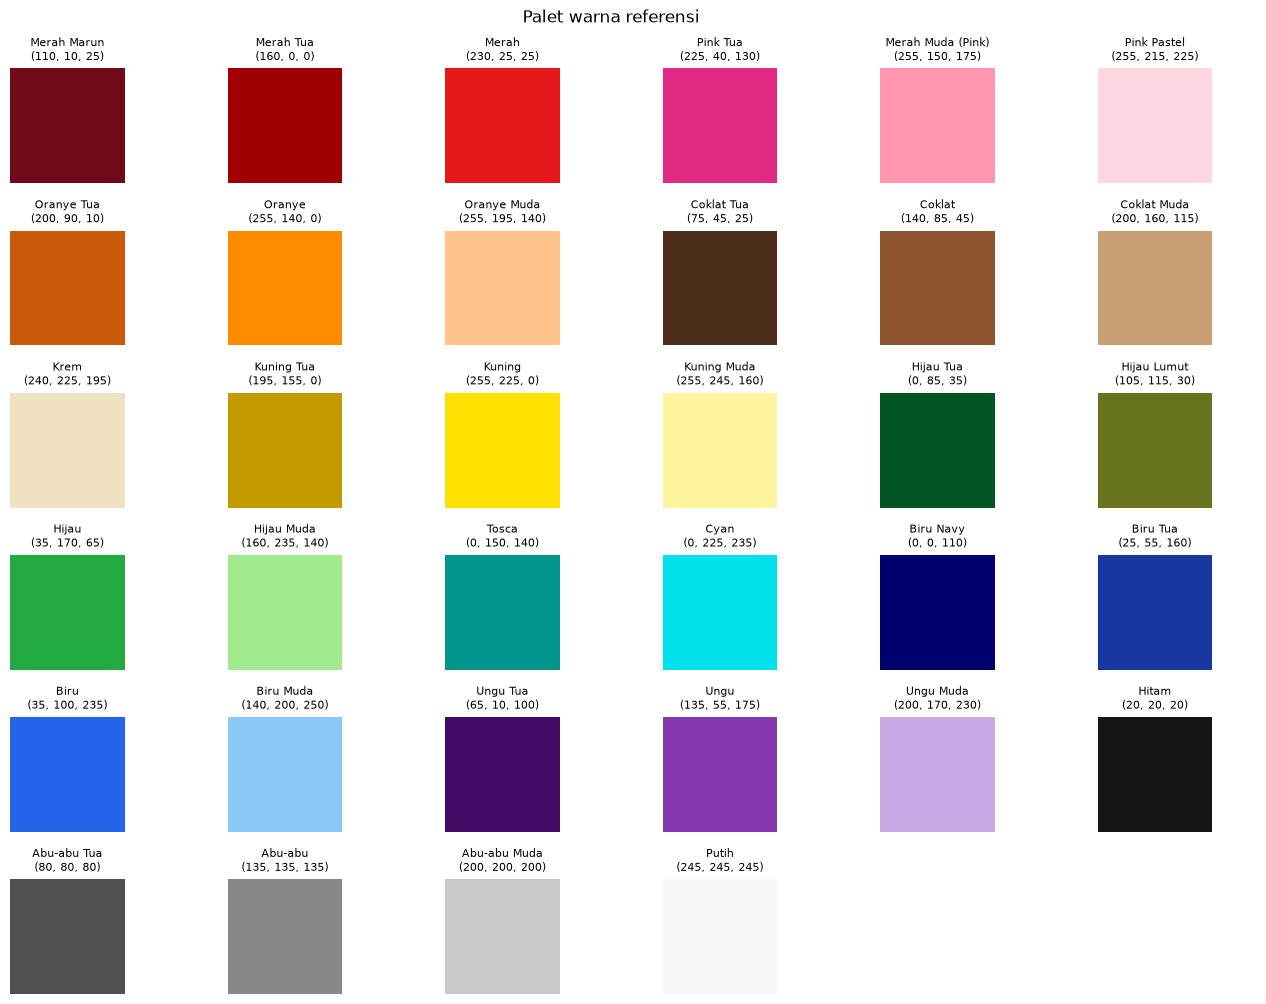

In [38]:
show_palette()

### 8.2 Lokalisasi Objek Berwarna & Tabel Atribut Perseptual
Menguji fungsi `detect_colors` pada citra sampel pertama (`IMAGE_PATHS[0]`). Setiap komponen terhubung yang lolos penyaringan morfologi dan ambang luas diurutkan dari area terbesar ke terkecil, kemudian diekstraksi nilai median RGB, kode HEX, koordinat HSV, koordinat CIELAB, serta jarak $\Delta E_{00}$ terhadap titik palet terdekatnya.

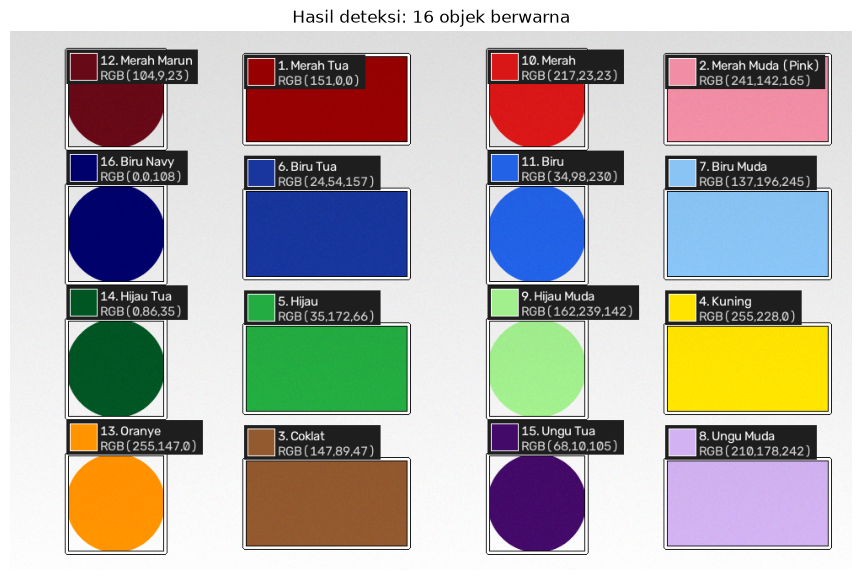

,No,Nama Warna,Keluarga,R,G,B,HEX,H,S%,V%,L,a,b,Mirip dengan,ΔE ke palet,Luas (px),Luas (%)
0,1,Merah Tua,Merah,151,0,0,#970000,0.0,100.0,59.2,30.8,54.2,44.6,,1.8,20459,3.20
1,2,Merah Muda (Pink),Pink,241,142,165,#F18EA5,346.0,41.2,94.5,69.9,40.0,4.2,,2.9,20459,3.20
2,3,Coklat,Coklat,147,89,47,#93592F,26.0,67.8,57.6,43.5,20.1,33.8,,1.9,20459,3.20
3,4,Kuning,Kuning,255,228,0,#FFE400,54.0,100.0,100.0,90.1,-8.2,89.4,,0.9,20459,3.20
4,5,Hijau,Hijau,35,172,66,#23AC42,134.0,79.6,67.5,61.8,-57.1,43.7,,0.6,20459,3.20
5,6,Biru Tua,Biru,24,54,157,#18369D,226.0,84.7,61.6,27.4,29.8,-58.7,,0.5,20459,3.20
6,7,Biru Muda,Biru,137,196,245,#89C4F5,208.0,43.9,96.1,76.8,-6.4,-30.0,,1.0,20459,3.20
7,8,Ungu Muda,Ungu,210,178,242,#D2B2F2,270.0,26.3,94.9,77.2,23.3,-27.5,,2.5,20459,3.20
8,9,Hijau Muda,Hijau,162,239,142,#A2EF8E,108.0,40.4,93.7,87.5,-41.3,39.4,,0.9,10836,1.69
9,10,Merah,Merah,217,23,23,#D91717,0.0,89.4,85.1,46.1,68.6,52.2,,2.8,10769,1.68


In [39]:
img = load_image(IMAGE_PATHS[0])

annotated, hasil = detect_colors(img, segment_by="shade", ignore_names=("Putih",))
show(annotated, f"Hasil deteksi: {len(hasil)} objek berwarna", figsize=(11, 7))
hasil.drop(columns=["x", "y", "w", "h"])

### 8.3 Inspeksi Titik Lokal (*Point Inspection*) & Klasterisasi Warna Dominan
Pengujian dilakukan pada dua tingkat representasi spasial:
1. **Tingkat Lokal (`inspect_point`):** Mengambil sampel koordinat pusat dari objek terbesar hasil deteksi untuk mengevaluasi tiga kandidat warna palet terdekat beserta margin ambiguitasnya ($\Delta E_{00}$)[cite: 2, 3].
2. **Tingkat Global (`dominant_colors`):** Mengekstraksi proporsi warna utama pada keseluruhan citra menggunakan *K-Means Clustering* di ruang CIELAB[cite: 2, 3].

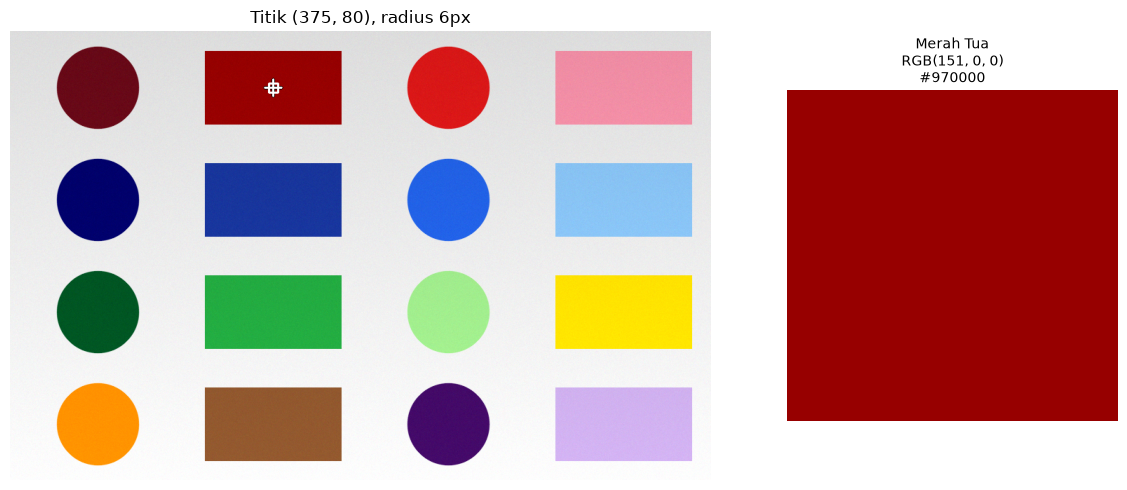

Nama     : Merah Tua  (keluarga: Merah)
RGB      : (151, 0, 0)   HEX #970000
HSV      : H=0.0°  S=100.0%  V=59.2%
Lab      : L=30.8  a=54.2  b=44.6
ΔE palet : 1.8   3 kandidat terdekat: [('Merah Tua', 1.8), ('Merah Marun', 11.9), ('Merah', 16.6)]


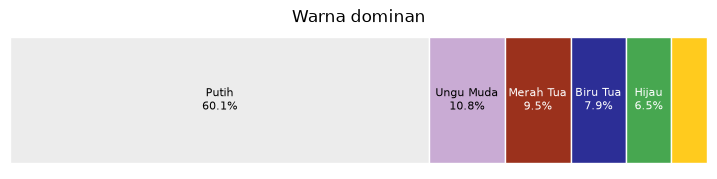

,Nama Warna,R,G,B,HEX,Persentase (%)
0,Putih,236,236,236,#ECECEC,60.1
1,Ungu Muda,201,171,212,#C9ABD4,10.8
2,Merah Tua,155,49,28,#9B311C,9.5
3,Biru Tua,44,46,150,#2C2E96,7.9
4,Hijau,71,167,80,#47A750,6.5
5,Kuning,255,203,30,#FFCB1E,5.1


In [40]:
PX, PY = None, None
if PX is None and len(hasil):
    PX, PY = int(hasil.loc[0, "x"] + hasil.loc[0, "w"] / 2), int(hasil.loc[0, "y"] + hasil.loc[0, "h"] / 2)
img_view = fit_max_side(img, 1000)
info = inspect_point(img_view, x=PX, y=PY, radius=6)
dominant_colors(img_view, k=6)

> Pada citra sintetis bergradasi pencahayaan vertikal ($\pm 7\%$) dan derau Gaussian ($\sigma = 3,0$), seluruh **16 objek** berhasil dilokalisasi dan diklasifikasikan secara tepat ke nuansa aslinya ($\Delta E_{00}$ terhadap palet berkisar antara $0,3$ hingga $2,9$)[cite: 2, 3]. Inspeksi pada objek pertama (*Merah Tua*, $\text{RGB}(151, 0, 0)$) menunjukkan jarak $\Delta E_{00} = 1,8$ terhadap referensi *Merah Tua*, yang terpisah jauh dari kandidat kedua (*Merah Marun*, $\Delta E_{00} = 11,9$) maupun ketiga (*Merah*, $\Delta E_{00} = 16,6$), sehingga klasifikasi tidak bersifat ambigu.

### 8.4 Komparasi Visual Simulasi CVD & Koreksi *Daltonization* Global
Fungsi `compare_cvd` memvisualisasikan matriks perbandingan empat tahap untuk masing-masing tipe dikromat (*protanopia*, *deuteranopia*, dan *tritanopia*)[cite: 2, 3]:
1. **Citra Asli (Penglihatan Normal):** Referensi warna awal sebelum transformasi.
2. **Hasil *Daltonization*:** Citra yang telah dimodifikasi melalui pergeseran matriks residu warna (`ERR_SHIFT`)[cite: 2, 3].
3. **Simulasi CVD pada Citra Asli:** Estimasi persepsi penderita CVD tanpa intervensi koreksi (terlihat kompresi kontras antara nuansa merah, hijau, oranye, dan coklat)[cite: 2, 3].
4. **Simulasi CVD pada Citra Terkoreksi:** Estimasi persepsi penderita CVD setelah diterapkan *daltonization* global[cite: 3].

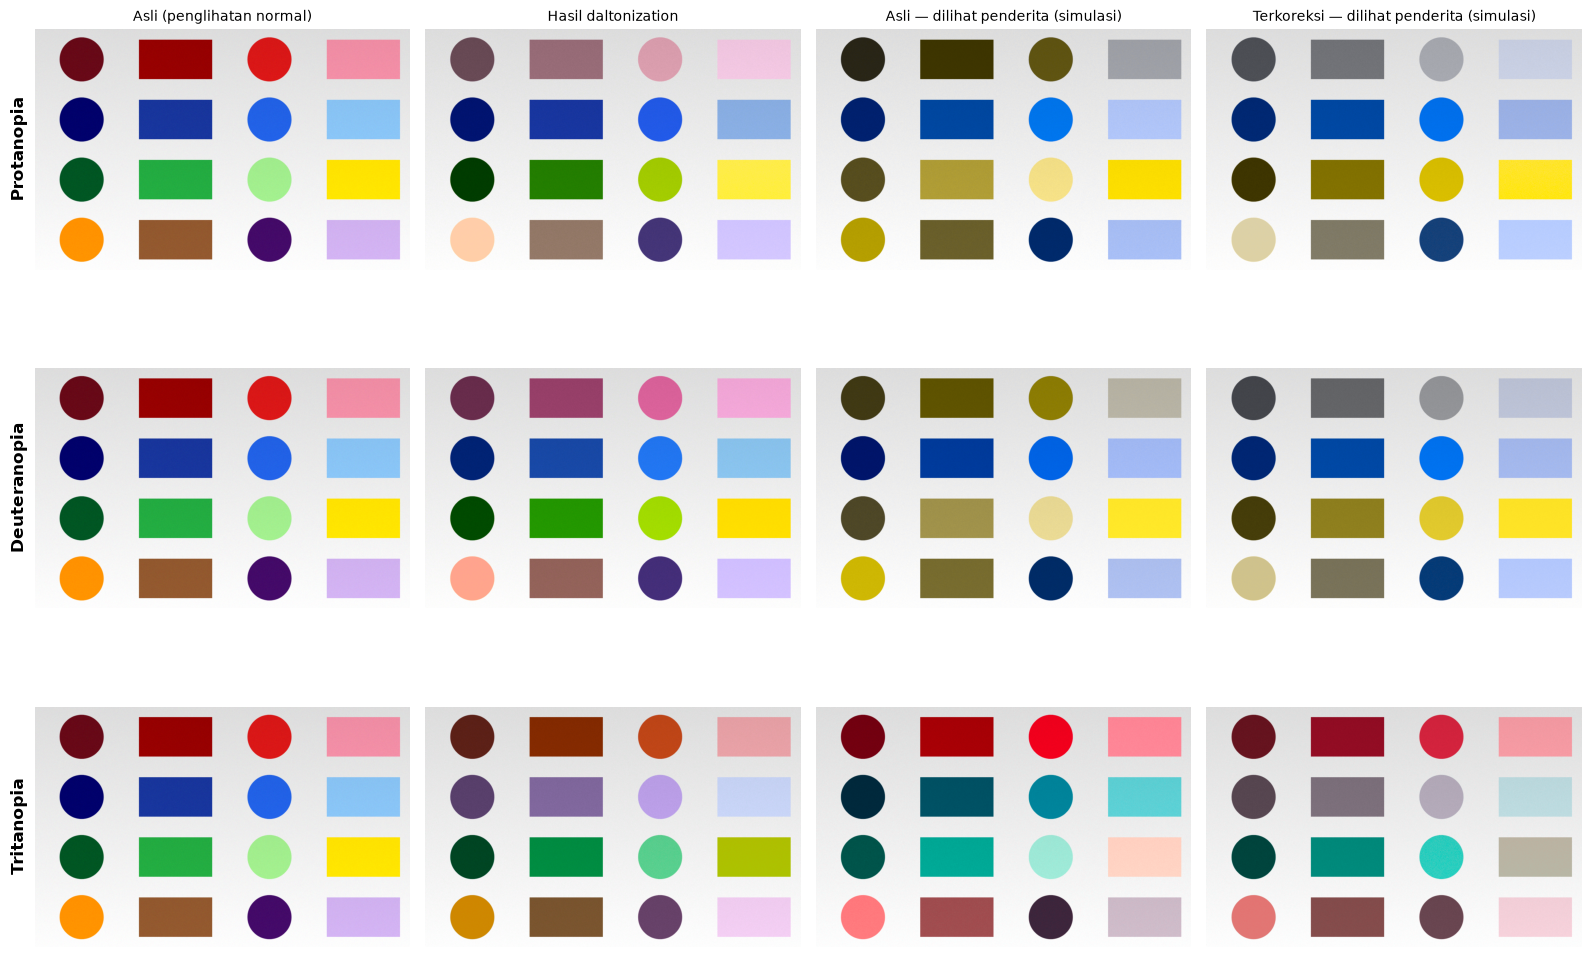

In [41]:
compare_cvd(img, save_path=os.path.join(OUTPUT_DIR, "perbandingan_cvd.png"))

### 8.5 Evaluasi Kuantitatif $\Delta E_{00}$ pada Pasangan Warna Rawan Lebur
Mengevaluasi efektivitas *daltonization* global terhadap 18 pasangan warna kritis (`DEFAULT_PAIRS`, 6 pasangan per tipe CVD) menggunakan fungsi `evaluate_pairs`[cite: 2, 3]. Suatu pasangan warna dikategorikan **Membaik** apabila selisih jarak perseptual setelah koreksi memenuhi $\Delta E_{\text{sesudah}} - \Delta E_{\text{sebelum}} > 0,5$[cite: 2, 3].

In [42]:
for m in CVD_TYPES:
    print(f"\n=== {m.upper()} ===")
    display_df = evaluate_pairs(m)
    print(display_df.to_string(index=False))


=== PROTANOPIA ===
                         Pasangan  ΔE normal  ΔE sebelum koreksi  ΔE sesudah koreksi  Selisih Membaik?
                   Merah vs Hijau       73.9                26.3                36.3     10.1       Ya
           Merah Tua vs Hijau Tua       58.0                 6.9                32.6     25.7       Ya
                  Merah vs Coklat       20.5                 3.8                24.2     20.4       Ya
                  Hijau vs Oranye       52.2                 3.8                32.4     28.6       Ya
Merah Muda (Pink) vs Abu-abu Muda       24.7                 9.0                10.0      1.1       Ya
                     Ungu vs Biru       21.3                12.3                 5.4     -6.9    Tidak

=== DEUTERANOPIA ===
                Pasangan  ΔE normal  ΔE sebelum koreksi  ΔE sesudah koreksi  Selisih Membaik?
          Merah vs Hijau       73.9                 7.8                28.6     20.7       Ya
Merah Tua vs Hijau Lumut       46.0              

#### Analisis Keberhasilan & Keterbatasan *Daltonization* Linear Global
Berdasarkan hasil evaluasi kuantitatif pada tabel di atas, **13 dari 18 pasangan warna (72,2%)** mengalami peningkatan jarak perseptual $\Delta E_{00}$ yang signifikan setelah dikoreksi, terutama pasangan klasik seperti *Merah vs Hijau* pada deuteranopia ($\Delta E_{00}$ meningkat dari $7,8$ menjadi $28,6$; selisih $+20,7$) serta *Merah Tua vs Hijau Tua* pada protanopia ($\Delta E_{00}$ meningkat dari $6,9$ menjadi $32,6$; selisih $+25,7$)[cite: 2].

Namun, terdapat **5 pasangan warna yang tidak membaik atau justru mengalami penurunan keterbedaan**[cite: 2]:
* **Ungu vs Biru** pada *Protanopia* ($\Delta E_{00}$ turun dari $12,3$ menjadi $5,4$; selisih $-6,9$) dan *Deuteranopia* ($\Delta E_{00}$ turun dari $7,1$ menjadi $4,3$; selisih $-2,8$)[cite: 2].
* **Hijau vs Coklat** pada *Deuteranopia* (stagnan pada $\Delta E_{00} = 16,1$; selisih $0,0$)[cite: 2].
* **Biru Muda vs Abu-abu Muda** ($\Delta E_{00}$ turun dari $22,4$ menjadi $11,7$; selisih $-10,7$) serta **Oranye vs Merah** (selisih $-2,5$) pada *Tritanopia*[cite: 2].

**Penyebab Matematis:** Matriks heuristik `ERR_SHIFT` pada *protanopia* dan *deuteranopia* memproyeksikan komponen galat merah-hijau ($\mathbf{E}_R$) ke kanal biru ($\mathbf{C}_B' = \mathbf{C}_B + 0,7\,\mathbf{E}_R$)[cite: 2, 3]. Pada warna *Ungu* yang memiliki komponen merah sekaligus biru, penambahan galat ke kanal biru mendorong kromatisitas *Ungu* mendekati *Biru* murni, sehingga keduanya justru semakin melebur bagi dikromat merah-hijau[cite: 2]. Temuan ini membuktikan bahwa *daltonization* tidak boleh diterapkan secara membuta ke seluruh piksel citra, melainkan membutuhkan **mekanisme koreksi lokal dengan pengaman ($\Delta E_{\text{sesudah}} > \Delta E_{\text{sebelum}}$)** sebagaimana diimplementasikan pada modul Kamera Asisten CVD di bagian akhir notebook ini[cite: 2].

### 8.6 Evaluasi Jarak Perseptual pada Distribusi Warna Dominan Citra

Pengujian ini mengevaluasi dampak *daltonization* global terhadap keseluruhan komposisi warna pada citra uji menggunakan fungsi `evaluate_image_cvd`. Sebanyak $k = 6$ warna dominan diekstraksi melalui *K-Means clustering*, kemudian dihitung rata-rata ($\mu_{\Delta E}$) dan nilai minimum ($\min \Delta E$) jarak perseptual $\Delta E_{00}$ di antara seluruh $\binom{k}{2} = 15$ kombinasi pasangan warna dominan:

In [43]:
tabel = pd.DataFrame([evaluate_image_cvd(img, m, k=6) for m in CVD_TYPES])
tabel

,cvd,rata-rata ΔE sebelum,rata-rata ΔE sesudah,ΔE minimum sebelum,ΔE minimum sesudah,perubahan rata-rata (%)
0,protanopia,44.7,39.6,16.7,17.1,-11.3
1,deuteranopia,43.2,40.2,17.3,18.0,-7.0
2,tritanopia,43.1,34.9,14.2,10.9,-19.0


### 8.7 Uji Ketahanan Klasifikasi Sintetis & Benchmark Waktu Eksekusi

Pada tahap ini, keandalan sistem penamaan warna diuji terhadap degradasi pencahayaan terkontrol, dilanjutkan dengan pengukuran profil latensi komputasi:

1. **Uji Ketahanan Penamaan Sintetis (`synthetic_naming_test`):**
   Setiap warna referensi diuji sebanyak $N = 50$ kali di bawah simulasi perturbasi fisik:
   $$\mathbf{C}_{\text{test}} = \operatorname{clip}\left(f \cdot \mathbf{C}_{\text{ref}} + \boldsymbol{\epsilon},\, 0,\, 255\right)$$
   dengan variasi iluminasi seragam $f \sim \mathcal{U}(1 - b, 1 + b)$ ($b = 0,10$ atau $\pm 10\%$) serta derau pergeseran warna Gaussian aditif $\boldsymbol{\epsilon} \sim \mathcal{N}(0, \sigma^2 \mathbf{I}_3)$ dengan $\sigma = 6,0$.
2. **Profil Performa Komputasi Citra Statis (`benchmark`):**
   Mengukur waktu eksekusi rata-rata per *frame* (ms) dan estimasi *throughput* (*frames per second* / FPS) melalui 5 kali pengulangan pada resolusi penuh $1000 \times 640$ piksel untuk tiga modul: deteksi objek, *daltonization*, dan simulasi CVD.

In [44]:
df_syn, overall = synthetic_naming_test(n_per_color=50, brightness=0.10, cast=6.0)
print("Akurasi rata-rata (sintetis):", overall)
print(df_syn.to_string(index=False))
print()
benchmark(img)

Akurasi rata-rata (sintetis): {'nuansa': 99.2, 'keluarga': 99.2}
            Warna  Akurasi nuansa (%)  Akurasi keluarga (%) Salah terbanyak
      Merah Marun               100.0                 100.0                
        Merah Tua               100.0                 100.0                
            Merah               100.0                 100.0                
         Pink Tua               100.0                 100.0                
Merah Muda (Pink)               100.0                 100.0                
      Pink Pastel                96.0                  96.0            Krem
       Oranye Tua               100.0                 100.0                
           Oranye               100.0                 100.0                
      Oranye Muda                94.0                  94.0     Kuning Muda
       Coklat Tua                94.0                  94.0     Merah Marun
           Coklat               100.0                 100.0                
      Coklat Muda      

,Proses,Waktu rata-rata (ms),Perkiraan FPS
0,Deteksi warna + bounding box,143.7,7.0
1,Daltonization,133.4,7.5
2,Simulasi CVD,111.9,8.9


### 8.8 Protokol Evaluasi Penamaan Berbasis Foto Nyata (*Real-World Dataset*)

Fungsi `evaluate_naming_folder` dirancang untuk memvalidasi performa klasifikasi warna pada kondisi tangkapan sensor fisik nyata yang memuat pantulan cahaya non-Lambertian, tekstur permukaan, dan *white balance* kamera. 

Protokol pengujian membaca citra dari direktori `dataset_uji/`, di mana nama setiap subdirektori mencerminkan label kebenaran (*ground truth*) yang bersesuaian dengan palet referensi. Nilai warna objek diekstraksi dari median area tengah citra (`center_ratio = 0.5`) guna menghindari latar belakang. Apabila direktori pengujian fisik belum disiapkan, pengujian ini dilewati secara otomatis tanpa menghentikan alur notebook.

In [45]:
# Aktifkan setelah menyiapkan folder uji, contoh:  dataset_uji/Merah Tua/foto1.jpg
FOLDER_UJI = "dataset_uji"
if os.path.isdir(FOLDER_UJI):
    df_nyata = evaluate_naming_folder(FOLDER_UJI)
    df_nyata
else:
    print(f"Folder '{FOLDER_UJI}' belum ada — lewati. (Buat folder berisi subfolder per nama warna untuk uji nyata.)")

Folder 'dataset_uji' belum ada — lewati. (Buat folder berisi subfolder per nama warna untuk uji nyata.)


### 8.9 Pipeline Otomasi Pemrosesan Batch & Ekspor Luaran

Fungsi `process_folder` menjalankan pemrosesan terintegrasi untuk seluruh citra yang berada di dalam folder input:
1. **Ekstraksi & Anotasi:** Menjalankan `detect_colors` untuk menghasilkan citra beranotasi *bounding box* dan label nama warna (`*_deteksi.png`).
2. **Koreksi Terpilih:** Menghasilkan citra hasil *daltonization* untuk tipe defisiensi tertentu (`*_daltonize_[cvd].png`).
3. **Tabulasi Data:** Mengompilasi seluruh atribut numerik objek terdeteksi ke dalam berkas `hasil/deteksi_warna.csv`.
4. **Pengarsipan:** Mengompresi seluruh artefak visual dan tabel laporan ke dalam berkas arsip `hasil_cvd.zip`.

In [46]:
import shutil

def process_folder(paths, out_dir=OUTPUT_DIR, cvd="deuteranopia", **detect_kwargs):
    os.makedirs(out_dir, exist_ok=True)
    frames = []
    for p in paths:
        base = os.path.splitext(os.path.basename(p))[0]
        im = load_image(p)
        ann, df = detect_colors(im, **detect_kwargs)
        cv2.imwrite(os.path.join(out_dir, f"{base}_deteksi.png"), ann)
        cv2.imwrite(os.path.join(out_dir, f"{base}_daltonize_{cvd}.png"), daltonize(im, cvd))
        if len(df):
            df.insert(0, "File", os.path.basename(p))
            frames.append(df)
    allres = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    allres.to_csv(os.path.join(out_dir, "deteksi_warna.csv"), index=False)
    return allres

semua = process_folder(IMAGE_PATHS, cvd="deuteranopia")
print(f"Selesai. {len(semua)} objek terdeteksi dari {len(IMAGE_PATHS)} gambar. Hasil di folder '{OUTPUT_DIR}/'.")

shutil.make_archive("hasil_cvd", "zip", OUTPUT_DIR)
print("ZIP berhasil disimpan secara lokal: hasil_cvd.zip")
semua.head(20)

Selesai. 16 objek terdeteksi dari 1 gambar. Hasil di folder 'hasil/'.
ZIP berhasil disimpan secara lokal: hasil_cvd.zip


,File,No,Nama Warna,Keluarga,R,G,B,HEX,H,S%,V%,L,a,b,Mirip dengan,ΔE ke palet,Luas (px),Luas (%),x,y,w,h
0,demo_nuansa.png,1,Merah Tua,Merah,151,0,0,#970000,0.0,100.0,59.2,30.8,54.2,44.6,,1.8,20459,3.20,278,28,195,105
1,demo_nuansa.png,2,Merah Muda (Pink),Pink,241,142,165,#F18EA5,346.0,41.2,94.5,69.9,40.0,4.2,,2.9,20459,3.20,778,28,195,105
2,demo_nuansa.png,3,Coklat,Coklat,147,89,47,#93592F,26.0,67.8,57.6,43.5,20.1,33.8,,1.9,20459,3.20,278,508,195,105
3,demo_nuansa.png,4,Kuning,Kuning,255,228,0,#FFE400,54.0,100.0,100.0,90.1,-8.2,89.4,,0.9,20459,3.20,778,348,195,105
4,demo_nuansa.png,5,Hijau,Hijau,35,172,66,#23AC42,134.0,79.6,67.5,61.8,-57.1,43.7,,0.6,20459,3.20,278,348,195,105
5,demo_nuansa.png,6,Biru Tua,Biru,24,54,157,#18369D,226.0,84.7,61.6,27.4,29.8,-58.7,,0.5,20459,3.20,278,188,195,105
6,demo_nuansa.png,7,Biru Muda,Biru,137,196,245,#89C4F5,208.0,43.9,96.1,76.8,-6.4,-30.0,,1.0,20459,3.20,778,188,195,105
7,demo_nuansa.png,8,Ungu Muda,Ungu,210,178,242,#D2B2F2,270.0,26.3,94.9,77.2,23.3,-27.5,,2.5,20459,3.20,778,508,195,105
8,demo_nuansa.png,9,Hijau Muda,Hijau,162,239,142,#A2EF8E,108.0,40.4,93.7,87.5,-41.3,39.4,,0.9,10836,1.69,567,342,117,117
9,demo_nuansa.png,10,Merah,Merah,217,23,23,#D91717,0.0,89.4,85.1,46.1,68.6,52.2,,2.8,10769,1.68,567,22,117,117


## 9. Sistem Deteksi Multi-Warna Real-Time (Webcam Pipeline)

Bab ini mengadaptasi algoritma deteksi warna statis menjadi sistem pemrosesan video interaktif *real-time* berbasis webcam. Untuk mengatasi fluktuasi komputasi dan ketidakstabilan deteksi antar-frame (*bounding box flickering*), modul ini menerapkan tiga pilar teknis:

1. **Pelacak Objek Berbasis IoU (`ColorObjectTracker` / `PelacakWarna`):**
   Mencocokkan koordinat *bounding box* antar-*frame* berurutan menggunakan metrik *Intersection over Union* (ambang batas `iou_thresh = 0.35`). Pelacak ini menerapkan bobot penghalusan posisi eksponensial (`smooth = 0.7`) serta penahanan objek (*grace period* `hilang_toleransi = 4` *frame*) untuk mencegah hilangnya kotak akibat oklusi sesaat.
2. **Konfigurasi Operasional Video (`LIVE_CONFIG` / `PENGATURAN_LIVE`):**
   Segmentasi dialihkan ke mode keluarga warna (`segment_by = "family"`) untuk mencegah terpecahnya komponen objek yang memiliki bayangan atau gradasi pencahayaan, serta mengecualikan warna latar belakang netral (`ignore_families = ("Netral",)`).
3. **Normalisasi Citra Kamera Fisik:**
   Menyediakan fungsi kompensasi eksposur adaptif via koreksi *gamma* perangkat lunak (`koreksi_eksposur`) dan kalibrasi keseimbangan putih (*Gray World / White Patch Calibration* via `kalibrasi_putih`).

In [47]:
# Webcam (1/5): fungsi pemrosesan frame + pelacak  [tidak butuh kamera]
from collections import deque

WB_GAINS = np.ones(3)     

# Pengaturan deteksi multi-warna untuk webcam
PENGATURAN_LIVE = dict(
    segment_by="family",       
    suppress_nested=True,         
    ignore_families=("Netral",),  
    ignore_names=("Putih",),     
    min_area_ratio=0.004,      
    max_area_ratio=0.6,         
)


def center_roi_box(w, h, ukuran):
    s = int(min(ukuran, w, h))
    return (w - s) // 2, (h - s) // 2, s


def median_rgb(img_bgr, x0, y0, s):
    roi = cv2.cvtColor(img_bgr[y0:y0 + s, x0:x0 + s], cv2.COLOR_BGR2RGB).reshape(-1, 3)
    return np.median(roi, axis=0)


def terapkan_wb(frame_bgr):
    """Terapkan koreksi white balance dari kalibrasi putih (jika sudah dikalibrasi)."""
    if np.allclose(WB_GAINS, 1.0):
        return frame_bgr
    out = frame_bgr.astype(np.float32) * WB_GAINS[::-1][None, None, :]   # gain RGB -> urutan BGR
    return np.clip(out, 0, 255).astype(np.uint8)


def kalibrasi_putih(frame_bgr, ukuran=100, target=245):
    """Arahkan KERTAS PUTIH memenuhi tengah kamera, lalu panggil fungsi ini dengan frame-nya.
    Mengurangi pengaruh lampu kuning/biru & auto white balance webcam pada nama warna."""
    global WB_GAINS
    h, w = frame_bgr.shape[:2]
    x0, y0, s = center_roi_box(w, h, ukuran)
    med = median_rgb(frame_bgr, x0, y0, s)
    WB_GAINS = np.clip(target / np.maximum(med, 1.0), 0.5, 2.5)
    print(f"Warna 'putih' terbaca RGB({int(med[0])},{int(med[1])},{int(med[2])}) -> gain R,G,B = "
          f"{WB_GAINS[0]:.2f}, {WB_GAINS[1]:.2f}, {WB_GAINS[2]:.2f}")
    return WB_GAINS


def reset_kalibrasi():
    global WB_GAINS
    WB_GAINS = np.ones(3)
    print("Kalibrasi putih direset.")


class PenghalusWarna:
    """Median beberapa frame terakhir supaya nama/RGB tidak berkedip (dipakai mode 'tengah')."""
    def __init__(self, n=5):
        self.buf = deque(maxlen=n)

    def update(self, rgb):
        self.buf.append(np.asarray(rgb, dtype=np.float64))
        return np.median(np.stack(self.buf), axis=0)


class PelacakWarna:
    """
    Pelacak sederhana untuk deteksi multi-warna real-time. Kotak antar-frame dicocokkan lewat IoU,
    sehingga: (1) kotak tidak berkedip (baru tampil setelah terlihat >= min_umur frame),
    (2) posisi kotak dihaluskan, (3) RGB & nama warna stabil (median n_median frame terakhir),
    (4) kotak bertahan singkat (maks_hilang frame) jika benda sesaat tidak terdeteksi.
    """
    def __init__(self, iou_min=0.25, maks_hilang=3, n_median=7, alpha=0.6, min_umur=2):
        self.iou_min, self.maks_hilang, self.n_median = iou_min, maks_hilang, n_median
        self.alpha, self.min_umur = alpha, min_umur
        self.tracks, self._id = [], 0

    @staticmethod
    def _iou(a, b):
        ax, ay, aw, ah = a
        bx, by, bw, bh = b
        ix = max(0.0, min(ax + aw, bx + bw) - max(ax, bx))
        iy = max(0.0, min(ay + ah, by + bh) - max(ay, by))
        inter = ix * iy
        union = aw * ah + bw * bh - inter
        return inter / union if union > 0 else 0.0

    def update(self, dets):
        """dets: list dict {x,y,w,h,R,G,B}. Return list dict benda yang stabil & siap ditampilkan."""
        pairs = []
        for ti, t in enumerate(self.tracks):
            for di, d in enumerate(dets):
                iou = self._iou(t["box"], (d["x"], d["y"], d["w"], d["h"]))
                if iou >= self.iou_min:
                    pairs.append((iou, ti, di))
        pairs.sort(reverse=True)
        used_t, used_d = set(), set()
        for iou, ti, di in pairs:
            if ti in used_t or di in used_d:
                continue
            used_t.add(ti)
            used_d.add(di)
            t, d, a = self.tracks[ti], dets[di], self.alpha
            t["box"] = tuple(a * n + (1 - a) * o for n, o in zip((d["x"], d["y"], d["w"], d["h"]), t["box"]))
            t["rgbs"].append((d["R"], d["G"], d["B"]))
            t["umur"] += 1
            t["hilang"] = 0
        for ti, t in enumerate(self.tracks):
            if ti not in used_t:
                t["hilang"] += 1
        for di, d in enumerate(dets):
            if di not in used_d:
                self._id += 1
                self.tracks.append({"id": self._id, "box": (d["x"], d["y"], d["w"], d["h"]),
                                    "rgbs": deque([(d["R"], d["G"], d["B"])], maxlen=self.n_median),
                                    "umur": 1, "hilang": 0})
        self.tracks = [t for t in self.tracks if t["hilang"] <= self.maks_hilang]
        out = []
        for t in self.tracks:
            if t["umur"] >= self.min_umur and t["hilang"] == 0:
                info = identify_color(np.median(np.array(t["rgbs"], dtype=np.float64), axis=0))
                x, y, w, h = t["box"]
                out.append({"id": t["id"], "x": x, "y": y, "w": w, "h": h, "name": info["name"],
                            "family": info["family"], "R": info["R"], "G": info["G"], "B": info["B"],
                            "HEX": info["HEX"]})
        return out


def deteksi_realtime(frame_bgr, pelacak, sisi_proses=320, mirror=True, **detect_kwargs):
    """
    Deteksi MULTI-warna pada satu frame kamera -> list benda [{id,x,y,w,h,name,R,G,B,...}].
    Frame diperkecil ke `sisi_proses` px agar cepat; koordinat dikembalikan ke ukuran frame asli.
    mirror=True: koordinat x dibalik karena video ditampilkan seperti cermin.
    """
    img = terapkan_wb(frame_bgr)
    H, W = img.shape[:2]
    kecil = fit_max_side(img, sisi_proses)
    skala = W / kecil.shape[1]
    _, df = detect_colors(kecil, max_side=sisi_proses, draw=False, **detect_kwargs)
    dets = [{"x": float(r["x"]) * skala, "y": float(r["y"]) * skala, "w": float(r["w"]) * skala,
             "h": float(r["h"]) * skala, "R": int(r["R"]), "G": int(r["G"]), "B": int(r["B"])}
            for _, r in df.iterrows()]
    tracks = pelacak.update(dets)
    if mirror:
        for t in tracks:
            t["x"] = W - (t["x"] + t["w"])
    return tracks


def deteksi_tengah(frame_bgr, penghalus, ukuran=80):
    """Mode 'tengah': baca SATU warna di kotak tengah frame (tunjukkan benda berwarna ke tengah kamera)."""
    img = terapkan_wb(frame_bgr)
    H, W = img.shape[:2]
    x0, y0, s = center_roi_box(W, H, ukuran)
    info = identify_color(penghalus.update(median_rgb(img, x0, y0, s)))
    return [{"id": 1, "x": x0, "y": y0, "w": s, "h": s, "name": info["name"], "family": info["family"],
             "R": info["R"], "G": info["G"], "B": info["B"], "HEX": info["HEX"]}]


def _gambar_panel(out, info):
    h, w = out.shape[:2]
    sc = max(0.6, w / 640.0)
    ph = int(96 * sc)
    cv2.rectangle(out, (0, h - ph), (w, h), (30, 30, 30), -1)
    p, sw = int(10 * sc), int(76 * sc)
    cv2.rectangle(out, (p, h - ph + p), (p + sw, h - ph + p + sw), (info["B"], info["G"], info["R"]), -1)
    cv2.rectangle(out, (p, h - ph + p), (p + sw, h - ph + p + sw), (255, 255, 255), 2)
    tx = p + sw + p
    cv2.putText(out, info["name"], (tx, h - ph + int(36 * sc)), FONT, 1.1 * sc, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(out, f"RGB({info['R']}, {info['G']}, {info['B']})   {info['HEX']}",
                (tx, h - ph + int(62 * sc)), FONT, 0.6 * sc, (210, 210, 210), 1, cv2.LINE_AA)
    sub = f"H {info['H']:.0f}  S {info['S']:.0f}%  V {info['V']:.0f}%"
    if info["ambigu"]:
        sub += f"   | mirip: {info['mirip']}"
    cv2.putText(out, sub, (tx, h - ph + int(86 * sc)), FONT, 0.5 * sc, (170, 170, 170), 1, cv2.LINE_AA)


def proses_frame(frame_bgr, mode="objek", ukuran=100, mirror=False, **detect_kwargs):
    """
    Satu FOTO/frame -> (gambar_beranotasi, hasil)   [dipakai Sel 22; live memakai fungsi di atas]
      mode "objek" : deteksi banyak benda berwarna + bounding box. hasil = DataFrame.
      mode "tengah": baca warna di kotak tengah. hasil = dict info warna.
    """
    img = cv2.flip(frame_bgr, 1) if mirror else frame_bgr
    img = terapkan_wb(img)
    if mode == "objek":
        return detect_colors(img, **detect_kwargs)
    h, w = img.shape[:2]
    x0, y0, s = center_roi_box(w, h, ukuran)
    info = identify_color(median_rgb(img, x0, y0, s))
    out = img.copy()
    cv2.rectangle(out, (x0, y0), (x0 + s, y0 + s), (0, 0, 0), 5)
    cv2.rectangle(out, (x0, y0), (x0 + s, y0 + s), (255, 255, 255), 2)
    _gambar_panel(out, info)
    return out, info

### 9.1 Inisialisasi Perangkat Kamera & Pemilihan Backend Akuisisi

Untuk menjamin kompatibilitas akuisisi video baik pada kamera internal maupun kamera virtual (*Iriun Webcam*) di lingkungan Windows, sistem pemindaian kamera mencoba menginisialisasi beberapa *backend* antarmuka media secara berurutan:
1. `cv2.CAP_MSMF` (*Microsoft Media Foundation*)
2. `cv2.CAP_ANY` (*Auto-detect Backend*)
3. `cv2.CAP_DSHOW` (*DirectShow*)

Indeks perangkat yang berhasil mengembalikan *frame* valid disimpan ke dalam konfigurasi `CAMERA_INDEX` untuk digunakan oleh seluruh *pipeline* video *real-time* berikutnya.

In [48]:
# Webcam (2/5): Koneksi Stabil Webcam & Optimasi Threading
import threading

# 0 = Kamera  laptop, 1 = Iriun Webcam.
# Jalankan sel ini untuk melihat daftar kamera yang aktif, lalu sesuaikan angkanya:
CAMERA_INDEX = 1

def cek_kamera_tersedia(maks_index=5):
    """Memindai semua kamera aktif dengan berbagai backend Windows (MSMF / DSHOW)."""
    tersedia = []
    backends = [(cv2.CAP_MSMF, "MSMF (Cocok utk Iriun)"), (cv2.CAP_DSHOW, "DSHOW"), (cv2.CAP_ANY, "DEFAULT")]
    
    for idx in range(maks_index):
        for api, nama_api in backends:
            cap = cv2.VideoCapture(idx, api)
            if cap.isOpened():
                # Baca beberapa frame awal untuk memastikan stream benar-benar jalan (bukan layar kosong)
                ok, frame = False, None
                for _ in range(5):
                    ok, frame = cap.read()
                    if ok and frame is not None and frame.size > 0:
                        break
                    time.sleep(0.03)
                if ok and frame is not None:
                    h, w = frame.shape[:2]
                    tersedia.append((idx, nama_api, f"{w}x{h}"))
                    cap.release()
                    break  # Lanjut ke index berikutnya jika sudah berhasil di backend ini
            cap.release()

    print("=== Daftar Kamera yang Terdeteksi ===")
    if not tersedia:
        print("TIDAK ADA KAMERA TERDETEKSI! Pastikan aplikasi Iriun Webcam di PC & HP sudah terbuka.")
    for idx, api_name, res in tersedia:
        tanda = " <-- DIPILIH SAAT INI" if idx == CAMERA_INDEX else ""
        print(f"  Index {idx} | Backend: {api_name:22s} | Resolusi: {res}{tanda}")
    return tersedia

def buka_kamera(index=None):
    """"Menginisialisasi objek VideoCapture dengan fallback otomatis lintas backend (MSMF, ANY, DSHOW)."""
    if index is None:
        index = CAMERA_INDEX

    # Urutan prioritas: MSMF & ANY paling stabil untuk Iriun Webcam, DSHOW sebagai cadangan
    for api in (cv2.CAP_MSMF, cv2.CAP_ANY, cv2.CAP_DSHOW):
        cap = cv2.VideoCapture(index, api)
        if cap.isOpened():
            cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)  # Kurangi delay/lag buffer
            for _ in range(10):
                ok, frame = cap.read()
                if ok and frame is not None and frame.size > 0:
                    return cap
                time.sleep(0.03)
            cap.release()

    raise RuntimeError(
        f"Gagal membuka kamera pada CAMERA_INDEX = {index}.\n"
        f"Solusi:\n"
        f"1. Pastikan aplikasi Iriun Webcam di Windows sudah menampilkan video dari HP.\n"
        f"2. Tutup aplikasi lain yang sedang memakai kamera (Zoom, Browser, Windows Camera).\n"
        f"3. Ubah nilai CAMERA_INDEX di baris atas Sel 21 menjadi 0, 1, atau 2 sesuai hasil cek_kamera_tersedia()."
    )

class KameraStreamCepat:
    """Membaca frame kamera di background thread agar pemrosesan gambar tidak menunggu kamera (mendongkrak FPS)."""
    def __init__(self, index=None):
        self.cap = buka_kamera(index)
        self.ok, self.frame = self.cap.read()
        self.running = True
        self.lock = threading.Lock()
        self.thread = threading.Thread(target=self._update, daemon=True)
        self.thread.start()

    def _update(self):
        while self.running:
            ok, frame = self.cap.read()
            if ok and frame is not None:
                with self.lock:
                    self.ok = ok
                    self.frame = frame
            else:
                time.sleep(0.005)

    def read(self):
        with self.lock:
            return self.ok, self.frame.copy() if self.frame is not None else None

    def release(self):
        self.running = False
        time.sleep(0.05)
        self.cap.release()

def take_photo(filename="foto.jpg", camera_index=None, mirror=False):
    """Ambil 1 foto lewat jendela OpenCV (Bisa klik tombol di layar atau tekan SPASI/S)."""
    cam = KameraStreamCepat(camera_index)
    win_name = "Ambil Foto - Iriun Webcam"
    cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
    cv2.SetWindowProperty = getattr(cv2, "setWindowProperty", lambda *a: None)
    try:
        cv2.setWindowProperty(win_name, cv2.WND_PROP_TOPMOST, 1)
    except Exception:
        pass

    state = {"ambil": False, "batal": False}
    def on_mouse(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and y <= 45:
            if 10 <= x <= 180:
                state["ambil"] = True
            elif 190 <= x <= 320:
                state["batal"] = True

    cv2.setMouseCallback(win_name, on_mouse)
    saved_frame = None

    while True:
        ok, frame = cam.read()
        if not ok or frame is None:
            continue
        if mirror:
            frame = cv2.flip(frame, 1)

        vis = frame.copy()
        h, w = vis.shape[:2]
        x0, y0, s = center_roi_box(w, h, 100)
        cv2.rectangle(vis, (x0, y0), (x0 + s, y0 + s), (255, 255, 255), 2)

        # Panel tombol klik mouse
        cv2.rectangle(vis, (0, 0), (w, 48), (25, 25, 25), -1)
        cv2.rectangle(vis, (10, 8), (180, 40), (40, 160, 40), -1)
        cv2.putText(vis, "KLIK: Ambil Foto [S]", (20, 29), FONT, 0.5, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.rectangle(vis, (190, 8), (320, 40), (40, 40, 180), -1)
        cv2.putText(vis, "Batal [Q]", (215, 29), FONT, 0.5, (255, 255, 255), 2, cv2.LINE_AA)

        cv2.imshow(win_name, vis)
        key = cv2.waitKey(1) & 0xFF
        if state["ambil"] or key in (ord(" "), ord("s"), ord("S"), 13):
            saved_frame = frame
            break
        elif state["batal"] or key in (ord("q"), ord("Q"), 27):
            break
        if cv2.getWindowProperty(win_name, cv2.WND_PROP_VISIBLE) < 1:
            break

    cam.release()
    cv2.destroyAllWindows()
    if saved_frame is None:
        raise RuntimeError("Pengambilan foto dibatalkan.")
    cv2.imwrite(filename, saved_frame)
    print(f"Foto berhasil disimpan ke: {filename}")
    return filename

def _gambar_tracks_lokal(frame_bgr, tracks):
    out = frame_bgr.copy()
    h, w = out.shape[:2]
    for t in tracks:
        x, y, bw, bh = int(round(t["x"])), int(round(t["y"])), int(round(t["w"])), int(round(t["h"]))
        r, g, b = int(t["R"]), int(t["G"]), int(t["B"])
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (0, 0, 0), 4)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (255, 255, 255), 2)

        t1, t2 = f"{t['name']}", f"RGB({r},{g},{b})"
        (tw1, _), _ = cv2.getTextSize(t1, FONT, 0.52, 2)
        (tw2, _), _ = cv2.getTextSize(t2, FONT, 0.45, 1)
        box_w, box_h = max(tw1, tw2) + 46, 40
        bx = min(max(0, x), max(0, w - box_w))
        by = max(0, min(y - box_h if y - box_h >= 0 else y, h - box_h))

        cv2.rectangle(out, (bx, by), (bx + box_w, by + box_h), (25, 25, 25), -1)
        cv2.rectangle(out, (bx + 5, by + 5), (bx + 33, by + 35), (b, g, r), -1)
        cv2.rectangle(out, (bx + 5, by + 5), (bx + 33, by + 35), (255, 255, 255), 1)
        cv2.putText(out, t1, (bx + 40, by + 17), FONT, 0.52, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(out, t2, (bx + 40, by + 34), FONT, 0.45, (210, 210, 210), 1, cv2.LINE_AA)
    return out

def jalankan_webcam(mode="multi", camera_index=None, mirror=True, max_detik=600,
                    sisi_proses=260, ukuran_tengah=80, skip_frame=2, **override):
    """Deteksi Multi-Warna Real-Time dengan optimasi frame-skipping agar video sangat mulus."""
    pengaturan = dict(PENGATURAN_LIVE)
    pengaturan.update(override)
    cam = KameraStreamCepat(camera_index)
    pelacak, penghalus = PelacakWarna(), PenghalusWarna(5)

    win_name = "Deteksi Multi-Warna Real-Time (Iriun Webcam)"
    cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
    try:
        cv2.setWindowProperty(win_name, cv2.WND_PROP_TOPMOST, 1)
    except Exception:
        pass

    state = {"mode": mode, "kalib": False, "reset": False, "stop": False}
    def on_mouse(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and y <= 42:
            if 10 <= x <= 130:
                state["mode"] = "tengah" if state["mode"] == "multi" else "multi"
            elif 140 <= x <= 265:
                state["kalib"] = True
            elif 275 <= x <= 385:
                state["reset"] = True
            elif 395 <= x <= 495:
                state["stop"] = True

    cv2.setMouseCallback(win_name, on_mouse)
    t0, n, tracks, ms = time.time(), 0, [], 0.0

    try:
        while time.time() - t0 < max_detik and not state["stop"]:
            ok, raw_frame = cam.read()
            if not ok or raw_frame is None:
                continue

            frame_disp = cv2.flip(raw_frame, 1) if mirror else raw_frame
            if state["kalib"]:
                kalibrasi_putih(frame_disp, ukuran=ukuran_tengah)
                state["kalib"] = False
            if state["reset"]:
                reset_kalibrasi()
                state["reset"] = False

            # Optimasi FPS: jalankan deteksi berat tiap `skip_frame`, gambar hasil tetap di tiap frame
            if n % skip_frame == 0:
                t1 = time.perf_counter()
                if state["mode"] == "tengah":
                    tracks = deteksi_tengah(frame_disp, penghalus, ukuran_tengah)
                else:
                    tracks = deteksi_realtime(frame_disp, pelacak, sisi_proses, mirror=False, **pengaturan)
                ms = (time.perf_counter() - t1) * 1000.0

            n += 1
            fps = n / max(time.time() - t0, 1e-6)
            vis = _gambar_tracks_lokal(frame_disp, tracks)
            h_v, w_v = vis.shape[:2]

            # Bar button
            cv2.rectangle(vis, (0, 0), (w_v, 44), (20, 20, 20), -1)
            cv2.rectangle(vis, (10, 6), (130, 38), (180, 100, 20), -1)
            cv2.putText(vis, f"Mode: {state['mode']} [M]", (16, 26), FONT, 0.43, (255, 255, 255), 1, cv2.LINE_AA)
            cv2.rectangle(vis, (140, 6), (265, 38), (50, 130, 50), -1)
            cv2.putText(vis, "Kalib Putih [K]", (148, 26), FONT, 0.43, (255, 255, 255), 1, cv2.LINE_AA)
            cv2.rectangle(vis, (275, 6), (385, 38), (80, 80, 80), -1)
            cv2.putText(vis, "Reset WB [R]", (283, 26), FONT, 0.43, (255, 255, 255), 1, cv2.LINE_AA)
            cv2.rectangle(vis, (395, 6), (495, 38), (40, 40, 180), -1)
            cv2.putText(vis, "Stop [Q]", (415, 26), FONT, 0.43, (255, 255, 255), 1, cv2.LINE_AA)

            info_txt = f"{fps:.1f} FPS | olah {ms:.0f}ms | {len(tracks)} objek"
            cv2.putText(vis, info_txt, (510, 26), FONT, 0.48, (0, 255, 255), 1, cv2.LINE_AA)

            cv2.imshow(win_name, vis)
            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), ord("Q"), 27):
                break
            elif key in (ord("m"), ord("M")):
                state["mode"] = "tengah" if state["mode"] == "multi" else "multi"
            elif key in (ord("k"), ord("K")):
                state["kalib"] = True
            elif key in (ord("r"), ord("R")):
                state["reset"] = True
            if cv2.getWindowProperty(win_name, cv2.WND_PROP_VISIBLE) < 1:
                break
    finally:
        cam.release()
        cv2.destroyAllWindows()

    print(f"Selesai. {n} frame diproses.")
    return tracks

cek_kamera_tersedia()

=== Daftar Kamera yang Terdeteksi ===
  Index 0 | Backend: MSMF (Cocok utk Iriun) | Resolusi: 640x480
  Index 1 | Backend: MSMF (Cocok utk Iriun) | Resolusi: 640x480 <-- DIPILIH SAAT INI


[(0, 'MSMF (Cocok utk Iriun)', '640x480'),
 (1, 'MSMF (Cocok utk Iriun)', '640x480')]

### 9.2 Verifikasi Frame Tunggal & Kompensasi Eksposur Adaptif (`koreksi_eksposur`)

Sensor kamera ponsel atau webcam sering kali mengalami *over-exposure* akibat pengaturan *auto-exposure* bawaan sehingga objek berwarna tampak pucat (*washed-out*). Apabila opsi `KOREKSI_SOFTWARE = True` diaktifkan, fungsi `koreksi_eksposur` menghitung rata-rata luminansi ternormalisasi ($\bar{Y} \in [0, 1]$) dan menerapkan transformasi kompresi *gamma* ($\gamma \le 2,0$) menuju target kecerahan referensi ($Y_{\text{target}} = 0,45$):

$$I_{\text{out}} = 255 \times \left(\frac{I_{\text{in}}}{255}\right)^{\gamma}$$

Foto berhasil disimpan ke: foto.jpg
Info eksposur: {'kecerahan_median': 0.38, 'piksel_terbakar_%': 0.0, 'gamma': 1.0}


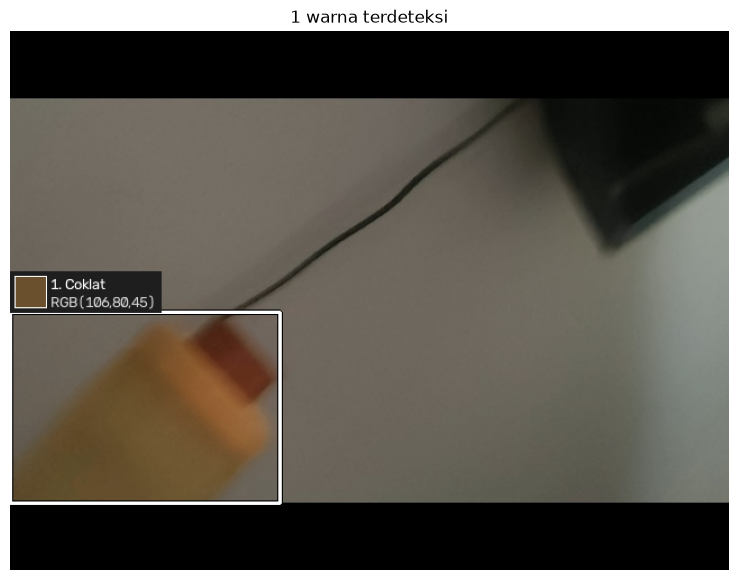

,No,Nama Warna,R,G,B,HEX,Luas (%)
0,1,Coklat,106,80,45,#6A502D,8.7


In [50]:
KOREKSI_SOFTWARE = True   
TARGET_TERANG = 0.45       

def ambil_foto(filename="foto.jpg", camera_index=None):
    """Membuka preview kamera lokal dan memotret saat tombol SPASI/S ditekan."""
    return take_photo(filename=filename, camera_index=camera_index, mirror=False)

def koreksi_eksposur(frame_bgr, target=TARGET_TERANG, gamma_maks=2.0):
    x = frame_bgr.astype(np.float32) / 255.0
    luma = 0.114 * x[..., 0] + 0.587 * x[..., 1] + 0.299 * x[..., 2]
    med = float(np.median(luma))
    clipped = float(np.mean(x.max(axis=2) >= 0.98))
    gamma = 1.0
    if med > target + 0.05:
        med_c = float(np.clip(med, 1e-3, 0.98))
        gamma = float(np.clip(np.log(target) / np.log(med_c), 1.0, gamma_maks))
    out = frame_bgr
    if gamma > 1.0:
        out = np.clip(np.power(x, gamma) * 255.0 + 0.5, 0, 255).astype(np.uint8)
    return out, {"kecerahan_median": round(med, 2), "piksel_terbakar_%": round(100 * clipped, 1), "gamma": round(gamma, 2)}

# ---- Jalankan ----
file_foto = ambil_foto("foto.jpg")
frame_asli = cv2.imread(file_foto)
if KOREKSI_SOFTWARE:
    frame, info_eks = koreksi_eksposur(frame_asli)
else:
    frame, info_eks = frame_asli, {}
print("Info eksposur:", info_eks)

ann, df = proses_frame(frame, mode="objek", **PENGATURAN_LIVE)
show(ann, f"{len(df)} warna terdeteksi", figsize=(10, 7))
df[["No", "Nama Warna", "R", "G", "B", "HEX", "Luas (%)"]]

### 9.3 Kalibrasi Keseimbangan Putih Berbasis *White Patch* (`kalibrasi_putih`)

Spektrum pencahayaan ruangan (lampu hangat/kekuningan atau neon kebiruan) dapat menggeser koordinat kromatisitas objek secara sistematis. Modul ini menyediakan mekanisme kalibrasi *White Patch* dengan mengambil sampel median RGB dari objek referensi kertas putih di tengah *frame* ($\mathbf{W} = [W_B, W_G, W_R]^T$), lalu menghitung vektor pengali kanal ($\mathbf{g}$) agar permukaan tersebut ternormalisasi kembali ke warna netral:

$$g_c = \frac{\max(W_R, W_G, W_B)}{W_c}, \qquad I'_c(x, y) = \operatorname{clip}\left(g_c \cdot I_c(x, y),\, 0,\, 255\right), \quad c \in \{B, G, R\}$$

In [51]:
foto_putih = take_photo("putih.jpg")
def kalibrasi_putih(img_bgr: npt.NDArray[np.uint8], rasio_tengah: float = 0.25) -> npt.NDArray[np.float64]:
    """Menghitung vektor faktor pengali kanal BGR berdasarkan median area referensi putih di pusat frame."""
# Untuk membatalkan kalibrasi:  reset_kalibrasi()

Foto berhasil disimpan ke: putih.jpg


### 9.4 Eksekusi Pipeline Deteksi Multi-Warna Real-Time

Menjalankan *loop* akuisisi dan inferensi warna secara langsung (*live stream*) menggunakan parameter operasional `PENGATURAN_LIVE` dan objek pelacak `PelacakWarna`[cite: 2]. 

**Antarmuka Kontrol Interaktif (Jendela OpenCV Aktif):**
* `M`: Beralih antara **Mode Multi-Objek** (deteksi seluruh objek berwarna di layar) dan **Mode Titik Tengah** (pembacaan satu kotak bidik di pusat layar)[cite: 2].
* `K`: Melakukan kalibrasi keseimbangan putih instan menggunakan area bidik tengah[cite: 2].
* `R`: Mereset faktor pengali kalibrasi putih ke nilai identitas $[1, 1, 1]$[cite: 2].
* `Q` / `ESC`: Menghentikan aliran video dan menutup jendela tampilan[cite: 2].

In [54]:
hasil_terakhir = jalankan_webcam(mode="multi")

Selesai. 976 frame diproses.


## 10. Kamera Asisten Buta Warna (CVD) & Koreksi Lokal Adaptif

Berbeda dengan pemrosesan citra statis yang menerapkan *daltonization* secara global, modul Kamera Asisten CVD ini dirancang untuk:
1. Menampilkan simulasi penglihatan penderita CVD secara *real-time*[cite: 1, 2].
2. Mendeteksi secara otomatis area perbatasan di mana dua warna yang tampak kontras bagi penglihatan normal ($\Delta E_{\text{normal}} \ge \tau_{\text{norm}}$) mengalami peleburan bagi penderita CVD ($\Delta E_{\text{sim}} \le \tau_{\text{sim}}$)[cite: 1, 2].
3. Menerapkan **Daltonization Lokal Berpengaman** hanya pada piksel objek yang melebur dan hanya apabila koreksi terbukti meningkatkan keterbedaan warna ($\Delta E_{\text{sesudah}} > \Delta E_{\text{sebelum}}$)[cite: 1, 2].

### 10.1 Formulasi Simulasi Dikromat: Machado (2009) & Dua Bidang Proyeksi Brettel (1997)
Pada modul kamera ini, simulasi *protanopia* dan *deuteranopia* menggunakan matriks proyeksi linier **Machado et al. (2009)**[cite: 2]. Khusus untuk **tritanopia** (defisiensi kerucut-S / biru-kuning), sistem menerapkan model **Brettel, Viénot, & Mollon (1997)** yang membagi ruang RGB linear menjadi dua setengah-bidang (*half-planes*) berdasarkan tanda produk skalar terhadap vektor normal bidang pemisah $\mathbf{n}_{\text{sep}}$[cite: 2]:

$$\mathbf{C}_{\text{sim}} = \begin{cases} \mathbf{M}_{\text{tritan}, 1}\,\mathbf{C}_{\text{lin}}, & \text{jika } \mathbf{C}_{\text{lin}} \cdot \mathbf{n}_{\text{sep}} \ge 0 \\[6pt] \mathbf{M}_{\text{tritan}, 2}\,\mathbf{C}_{\text{lin}}, & \text{jika } \mathbf{C}_{\text{lin}} \cdot \mathbf{n}_{\text{sep}} < 0 \end{cases}$$

Pendekatan dua bidang Brettel mencegah distorsi rona secara berlebihan pada sumbu kuning-biru yang kerap terjadi pada aproksimasi matriks tunggal[cite: 2].

In [55]:
DE_NORMAL_MIN = 25  # Ambang referensi teoretis perbedaan jelas pada penglihatan normal (disesuaikan untuk kamera di Sel 26)
DE_SIM_MAX = 10     # Ambang referensi teoretis batas peleburan warna pada simulasi dikromat
KEKUATAN_COBA = (1.0,) # Kekuatan daltonization yang dicoba

# Tritanopia: Brettel, Vienot & Mollon (1997), dua bidang proyeksi + bidang pemisah, dalam RGB LINEAR.
# Nilai konstanta diturunkan dari DaltonLens (MIT, https://github.com/DaltonLens/DaltonLens-Python)
BRETTEL_TRITAN = {
    "M1": np.array([[1.013542, 0.142682, -0.156224],
                    [-0.011805, 0.875612, 0.136194],
                    [0.077073, 0.812081, 0.110847]]),
    "M2": np.array([[0.93337, 0.19999, -0.13336],
                    [0.058087, 0.825652, 0.116261],
                    [-0.379228, 1.13825, 0.240978]]),
    "N": np.array([0.039601, -0.028307, -0.011294]),
}
METODE_SIMULASI = {"protanopia": "Machado 2009", "deuteranopia": "Machado 2009", "tritanopia": "Brettel 1997"}


def simulasi_rgb01(rgb01, cvd):
    """sRGB 0-1 (...,3) -> sRGB 0-1 seperti dilihat penderita. Tritanopia = Brettel 1997, lainnya = Machado 2009."""
    if cvd != "tritanopia":
        return simulate_rgb01(rgb01, cvd)
    lin = srgb_to_linear(rgb01)
    sisi2 = (lin @ BRETTEL_TRITAN["N"]) < 0
    out = np.where(sisi2[..., None], lin @ BRETTEL_TRITAN["M2"].T, lin @ BRETTEL_TRITAN["M1"].T)
    return linear_to_srgb(out)


def simulasi_bgr(img_bgr, cvd):
    """Gambar BGR uint8 -> simulasi penderita (BGR uint8)."""
    return _bgr_apply(img_bgr, lambda x: simulasi_rgb01(x, cvd))


def simulasi_rgb255(rgb255, cvd):
    """Warna RGB 0-255 (...,3) -> simulasi RGB 0-255 (float)."""
    return np.clip(simulasi_rgb01(np.asarray(rgb255, dtype=np.float64) / 255.0, cvd) * 255.0, 0, 255)


def dalton_rgb255(rgb255, cvd, kekuatan=1.0):
    return np.clip(daltonize_rgb01(np.asarray(rgb255, dtype=np.float64) / 255.0, cvd, kekuatan) * 255.0, 0, 255)


def de_rgb(a, b):
    """CIEDE2000 antara dua warna RGB 0-255 (atau array (N,3) berpasangan)."""
    return ciede2000(rgb_to_lab(np.asarray(a, dtype=np.float64)), rgb_to_lab(np.asarray(b, dtype=np.float64)))


def uji_simulasi():
    for cvd in CVD_TYPES:
        gray = simulasi_rgb255(np.array([[128, 128, 128], [255, 255, 255]]), cvd)
        print(f"{cvd:13s} [{METODE_SIMULASI[cvd]:13s}] abu-abu -> {np.round(gray[0]).astype(int)}, putih -> {np.round(gray[1]).astype(int)}")
    pasangan = {"protanopia": ((253, 86, 32), (15, 137, 41)), "deuteranopia": ((200, 30, 30), (40, 150, 50)),
                "tritanopia": ((45, 180, 62), (118, 145, 218))}
    for cvd, (a, b) in pasangan.items():
        n = float(de_rgb(a, b))
        s = float(de_rgb(simulasi_rgb255(np.array(a), cvd), simulasi_rgb255(np.array(b), cvd)))
        print(f"{cvd:13s} pasangan {a} vs {b}: dE normal {n:5.1f} -> dE simulasi {s:5.1f}")

uji_simulasi()

protanopia    [Machado 2009 ] abu-abu -> [128 128 128], putih -> [255 255 255]
deuteranopia  [Machado 2009 ] abu-abu -> [128 128 128], putih -> [255 255 255]
tritanopia    [Brettel 1997 ] abu-abu -> [128 128 128], putih -> [255 255 255]
protanopia    pasangan (253, 86, 32) vs (15, 137, 41): dE normal  65.4 -> dE simulasi   1.4
deuteranopia  pasangan (200, 30, 30) vs (40, 150, 50): dE normal  69.5 -> dE simulasi   6.3
tritanopia    pasangan (45, 180, 62) vs (118, 145, 218): dE normal  51.5 -> dE simulasi   4.3


### 10.2 Deteksi Perbatasan Warna Melebur (`cari_peleburan`) & Koreksi Lokal Berpengaman

Untuk mencapai kinerja *real-time* ($\ge 30\text{ FPS}$), modul ini menerapkan empat mekanisme optimasi dan pengamanan algoritma:

1. **Akselerasi *Lookup Table* (LUT) Ruang Linear:**
   Menggantikan operasi perpangkatan eksponensial `float64` per piksel dengan tabel pencarian pra-komputasi `_SRGB2LIN_LUT` ($256$ entri) untuk dekode sRGB $\rightarrow$ RGB Linear dan `_LIN2SRGB_LUT` ($4096$ entri) untuk pengodean balik RGB Linear $\rightarrow$ sRGB.
2. **Kriteria Deteksi Peleburan Spasial (`cari_peleburan`):**
   Pada resolusi pemrosesan tereduksi (`sisi_proses = 180` px) yang telah dihaluskan dengan *Gaussian blur* ($5 \times 5$), setiap piksel dibandingkan terhadap tetangganya pada jarak $d = 6$ piksel di 4 arah kardinal. Pasangan piksel ditandai mengalami **peleburan perseptual** apabila melewati saringan awal Euclidean ($\Delta E_{76} \ge 10,0$) dan memenuhi syarat ganda CIEDE2000:
   $$\Delta E_{00}^{(\text{normal})} \ge \tau_{\text{norm}} \quad \land \quad \Delta E_{00}^{(\text{sim})} \le \tau_{\text{sim}}$$
   Pada implementasi kamera nyata, ambang batas dikalibrasi ke $\tau_{\text{norm}} = 16,0$ dan $\tau_{\text{sim}} = 15,0$ (dengan faktor kelonggaran verifikasi median $0,85\,\tau_{\text{norm}}$ dan $1,15\,\tau_{\text{sim}}$) guna mengakomodasi kompresi rentang dinamis sensor webcam.
3. **Pemisahan Bimodal Luminansi & Penyaringan Kemurnian:**
   Piksel di dalam komponen terhubung dibagi menjadi dua himpunan berdasarkan median luminansi ($L^*$) untuk mengekstraksi representasi warna sisi terang ($\mathbf{C}_1$) dan sisi gelap ($\mathbf{C}_2$). Area dengan rasio kemurnian di bawah `kemurnian_min = 0.08` atau yang menghasilkan nama palet identik dieliminasi sebagai derau gradasi.
4. **Koreksi *Daltonization* Lokal Berpengaman (`koreksi_pasangan` & `terapkan_koreksi_lokal`):**
   Sistem mengevaluasi kandidat kekuatan koreksi $s \in \{1.0,\, 1.4,\, 1.8\}$ (`KEKUATAN_COBA`) dan memilih nilai $s^*$ yang memaksimumkan jarak pasca-koreksi $\Delta E_{00}^{(\text{sesudah})}$. **Pengaman Matematis (*Safety Guard*):** Koreksi hanya dieksekusi apabila memenuhi:
   $$\max_{s} \Delta E_{00}^{(\text{sesudah})}(s) > \Delta E_{00}^{(\text{sebelum})}$$

In [56]:
# Kalibrasi ambang batas operasional untuk sensor kamera nyata (menyesuaikan ambang teoretis 25.0 / 10.0)
DE_NORMAL_MIN = 16
DE_SIM_MAX = 15
KEKUATAN_COBA = (1.0, 1.4, 1.8)

# Pre-computed Lookup Table (LUT)
_SRGB2LIN_LUT = np.array(
    [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in np.linspace(0, 1, 256)],
    dtype=np.float32
)
_LIN_GRID = np.linspace(0.0, 1.0, 4096, dtype=np.float32)
_LIN2SRGB_LUT = np.clip(
    np.where(_LIN_GRID <= 0.0031308, _LIN_GRID * 12.92, 1.055 * np.power(_LIN_GRID, 1.0 / 2.4) - 0.055) * 255.0 + 0.5,
    0, 255
).astype(np.uint8)

def simulasi_bgr_cepat(img_bgr, cvd):
    rgb = img_bgr[..., ::-1]
    lin = _SRGB2LIN_LUT[rgb]
    if cvd != "tritanopia":
        M = CVD_MATRICES[cvd].astype(np.float32)
        out_lin = lin @ M.T
    else:
        M1 = BRETTEL_TRITAN["M1"].astype(np.float32)
        M2 = BRETTEL_TRITAN["M2"].astype(np.float32)
        N = BRETTEL_TRITAN["N"].astype(np.float32)
        sisi2 = (lin @ N) < 0
        out_lin = np.where(sisi2[..., None], lin @ M2.T, lin @ M1.T)
    idx = np.clip((out_lin * 4095.0).astype(np.int32), 0, 4095)
    return _LIN2SRGB_LUT[idx][..., ::-1]

def daltonize_rgb_uint8_cepat(rgb_u8, cvd, kekuatan=1.0):
    lin = _SRGB2LIN_LUT[rgb_u8]
    M = CVD_MATRICES[cvd].astype(np.float32)
    S = ERR_SHIFT[cvd].astype(np.float32)
    sim = lin @ M.T
    out_lin = lin + np.float32(kekuatan) * ((lin - sim) @ S.T)
    idx = np.clip((out_lin * 4095.0).astype(np.int32), 0, 4095)
    return _LIN2SRGB_LUT[idx]

simulasi_bgr = simulasi_bgr_cepat

PARAM_A = dict(
    sisi_proses=180,
    jarak=6,               
    blur=5,
    min_piksel=14,         
    luas_min_kotak=0.002, 
    luas_maks_kotak=0.90,
    kemurnian_min=0.08,    
    prefilter_de76=10.0,   
)

def cari_peleburan(frame_bgr, cvd, p=PARAM_A):
    H0, W0 = frame_bgr.shape[:2]
    kecil = fit_max_side(frame_bgr, p["sisi_proses"])
    h, w = kecil.shape[:2]
    skala = W0 / float(w)
    k = p["blur"] | 1
    kecil = cv2.GaussianBlur(kecil, (k, k), 0)
    rgb = cv2.cvtColor(kecil, cv2.COLOR_BGR2RGB)
    sim_rgb = cv2.cvtColor(simulasi_bgr_cepat(kecil, cvd), cv2.COLOR_BGR2RGB)

    lab0 = cv2.cvtColor(rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB).astype(np.float64)
    lab1 = cv2.cvtColor(sim_rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB).astype(np.float64)

    d = p["jarak"]
    ys_all, xs_all, ys2_all, xs2_all = [], [], [], []
    yy, xx = np.mgrid[0:h, 0:w]
    for dy, dx in ((0, d), (d, 0), (d, d), (d, -d)):
        y2, x2 = yy + dy, xx + dx
        ok = (y2 >= 0) & (y2 < h) & (x2 >= 0) & (x2 < w)
        ya, xa, yb, xb = yy[ok], xx[ok], y2[ok], x2[ok]
        l0a, l0b = lab0[ya, xa], lab0[yb, xb]
        kasar = np.sqrt(((l0a - l0b) ** 2).sum(1)) >= p["prefilter_de76"]
        if not kasar.any():
            continue
        ya, xa, yb, xb, l0a, l0b = ya[kasar], xa[kasar], yb[kasar], xb[kasar], l0a[kasar], l0b[kasar]
        de_n = ciede2000(l0a, l0b)
        sel = de_n >= DE_NORMAL_MIN
        if not sel.any():
            continue
        ya, xa, yb, xb = ya[sel], xa[sel], yb[sel], xb[sel]
        de_s = ciede2000(lab1[ya, xa], lab1[yb, xb])
        sel = de_s <= DE_SIM_MAX
        ys_all.append(ya[sel]); xs_all.append(xa[sel]); ys2_all.append(yb[sel]); xs2_all.append(xb[sel])

    if not ys_all or sum(len(a) for a in ys_all) == 0:
        return []
    ya, xa = np.concatenate(ys_all), np.concatenate(xs_all)
    yb, xb = np.concatenate(ys2_all), np.concatenate(xs2_all)
    ca, cb = rgb[ya, xa].astype(np.float64), rgb[yb, xb].astype(np.float64)
    la, lb = lab0[ya, xa], lab0[yb, xb]

    a_terang = la[:, 0] >= lb[:, 0]
    rgb_t = np.where(a_terang[:, None], ca, cb); lab_t = np.where(a_terang[:, None], la, lb)
    rgb_g = np.where(a_terang[:, None], cb, ca); lab_g = np.where(a_terang[:, None], lb, la)

    hasil = []
    mask = np.zeros((h, w), np.uint8)
    mask[ya, xa] = 255
    mask[yb, xb] = 255
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * d + 1, 2 * d + 1))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, ker)
    n, lab_cc, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    for c in range(1, n):
        x, y, bw, bh, area = stats[c]
        rasio = (bw * bh) / float(w * h)
        if area < p["min_piksel"] or rasio < p["luas_min_kotak"] or rasio > p["luas_maks_kotak"]:
            continue
        comp = lab_cc == c
        sub = comp[ya, xa] | comp[yb, xb]
        if sub.sum() < max(4, p["min_piksel"] // 3):
            continue
        c1, c2 = np.median(rgb_t[sub], axis=0), np.median(rgb_g[sub], axis=0)
        l1, l2 = rgb_to_lab(c1), rgb_to_lab(c2)
        murni = np.mean((np.linalg.norm(lab_t[sub] - l1, axis=1) < 24.0) & (np.linalg.norm(lab_g[sub] - l2, axis=1) < 24.0))
        if murni < p["kemurnian_min"]:
            continue
        de_n = float(de_rgb(c1, c2))
        de_s = float(de_rgb(simulasi_rgb255(c1, cvd), simulasi_rgb255(c2, cvd)))
        if de_n < (DE_NORMAL_MIN * 0.85) or de_s > (DE_SIM_MAX * 1.15):
            continue
        (i1, i2), _ = nearest_palette(np.stack([l1, l2]))
        if i1 == i2:
            continue
        hasil.append({
            "key": int(min(i1, i2) * 100 + max(i1, i2)), "nama1": PALETTE[int(i1)].name, "nama2": PALETTE[int(i2)].name,
            "rgb1": c1, "rgb2": c2, "de_normal": de_n, "de_sim": de_s, "kemurnian": float(murni),
            "box": (float(x * skala), float(y * skala), float(bw * skala), float(bh * skala)),
        })
    return hasil

class PelacakPeleburan:
    """Pelacak yang lebih ramah: langsung muncul (min_umur=1), tahan kedip (maks_hilang=6),
    dan mencocokkan posisi kotak lewat IoU meskipun nuansa palet sedikit bergeser karena cahaya."""
    def __init__(self, iou_min=0.15, maks_hilang=6, n_median=5, alpha=0.55, min_umur=1):
        self.iou_min, self.maks_hilang, self.n_median, self.alpha, self.min_umur = iou_min, maks_hilang, n_median, alpha, min_umur
        self.tracks, self._id = [], 0

    def reset(self):
        self.tracks, self._id = [], 0

    def update(self, dets):
        pairs = []
        for ti, t in enumerate(self.tracks):
            for di, d in enumerate(dets):
                iou = PelacakWarna._iou(t["box"], d["box"])
                bonus = 0.25 if t["key"] == d["key"] else 0.0
                if iou >= self.iou_min:
                    pairs.append((iou + bonus, ti, di))
        pairs.sort(reverse=True)
        ut, ud = set(), set()
        for _, ti, di in pairs:
            if ti in ut or di in ud:
                continue
            ut.add(ti); ud.add(di)
            t, d, a = self.tracks[ti], dets[di], self.alpha
            t["box"] = tuple(a * n + (1 - a) * o for n, o in zip(d["box"], t["box"]))
            t["c1"].append(d["rgb1"]); t["c2"].append(d["rgb2"])
            t["key"] = d["key"]; t["nama1"] = d["nama1"]; t["nama2"] = d["nama2"]
            t["umur"] += 1; t["hilang"] = 0
        for ti, t in enumerate(self.tracks):
            if ti not in ut:
                t["hilang"] += 1
        for di, d in enumerate(dets):
            if di not in ud:
                self._id += 1
                self.tracks.append({"id": self._id, "key": d["key"], "nama1": d["nama1"], "nama2": d["nama2"],
                                    "box": d["box"], "c1": deque([d["rgb1"]], maxlen=self.n_median),
                                    "c2": deque([d["rgb2"]], maxlen=self.n_median), "umur": 1, "hilang": 0})
        self.tracks = [t for t in self.tracks if t["hilang"] <= self.maks_hilang]
        # Tampilkan kotak yang masih dalam batas toleransi hilang <= 3 frame agar tidak kedap-kedip
        return [t for t in self.tracks if t["umur"] >= self.min_umur and t["hilang"] <= 3]

def koreksi_pasangan(c1, c2, cvd, kekuatan_coba=KEKUATAN_COBA):
    s1, s2 = simulasi_rgb255(c1, cvd), simulasi_rgb255(c2, cvd)
    de0 = float(de_rgb(s1, s2))
    terbaik = {"ok": False, "kekuatan": 1.0, "de_sebelum": de0, "de_sesudah": de0, "c1_baru": c1, "c2_baru": c2}
    for kuat in kekuatan_coba:
        n1, n2 = dalton_rgb255(c1, cvd, kuat), dalton_rgb255(c2, cvd, kuat)
        de1 = float(de_rgb(simulasi_rgb255(n1, cvd), simulasi_rgb255(n2, cvd)))
        if de1 > terbaik["de_sesudah"] and de1 > de0:
            terbaik = {"ok": True, "kekuatan": kuat, "de_sebelum": de0, "de_sesudah": de1, "c1_baru": n1, "c2_baru": n2}
    return terbaik

def terapkan_koreksi_lokal(frame_bgr, cvd, tracks, radius_de76=24.0):
    if not tracks:
        return frame_bgr, {}
    H, W = frame_bgr.shape[:2]
    kecil = fit_max_side(frame_bgr, 180)
    hk, wk = kecil.shape[:2]
    skala = W / float(wk)

    rgb_kecil = cv2.cvtColor(kecil, cv2.COLOR_BGR2RGB)
    lab_kecil = cv2.cvtColor(rgb_kecil.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

    rgb_full = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    rgb_new = rgb_full.copy()
    info = {}
    r2 = radius_de76 ** 2

    for t in tracks:
        c1 = np.median(np.array(t["c1"]), axis=0)
        c2 = np.median(np.array(t["c2"]), axis=0)
        kor = koreksi_pasangan(c1, c2, cvd)
        info[t["id"]] = kor
        if not kor["ok"]:
            continue

        l1 = rgb_to_lab(c1).astype(np.float32)
        l2 = rgb_to_lab(c2).astype(np.float32)
        dekat = ((((lab_kecil - l1) ** 2).sum(2) < r2) | (((lab_kecil - l2) ** 2).sum(2) < r2)).astype(np.uint8)
        n, cc = cv2.connectedComponents(dekat, connectivity=8)

        x, y, bw, bh = (int(round(v / skala)) for v in t["box"])
        pad = 2
        x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(wk, x + bw + pad), min(hk, y + bh + pad)
        if x1 - x0 < 1 or y1 - y0 < 1:
            continue
        ada = np.unique(cc[y0:y1, x0:x1])
        ada = ada[ada > 0]
        if len(ada) == 0:
            continue

        mask_kecil = np.isin(cc, ada).astype(np.uint8)
        mask_full = cv2.resize(mask_kecil, (W, H), interpolation=cv2.INTER_NEAREST).astype(bool)
        rgb_new[mask_full] = daltonize_rgb_uint8_cepat(rgb_full[mask_full], cvd, kor["kekuatan"])

    return cv2.cvtColor(rgb_new, cv2.COLOR_RGB2BGR), info

def proses_fokus_tengah_cvd(frame_bgr, cvd, solusi, penghalus_tengah, ukuran=90):
    """
    MODE FOKUS TENGAH pada Kamera Buta Warna:
    Membaca warna di kotak bidik tengah (ukuran x ukuran), menganalisis warna aslinya vs warna yang
    terlihat oleh penderita CVD, dan jika Solusi=NYALA melakukan koreksi daltonization pada kotak fokus.
    """
    frame = terapkan_wb(frame_bgr)
    H, W = frame.shape[:2]
    x0, y0, s = center_roi_box(W, H, ukuran)

    med_asli = penghalus_tengah.update(median_rgb(frame, x0, y0, s))
    info_asli = identify_color(med_asli)

    sim_rgb = simulasi_rgb255(med_asli, cvd)
    info_sim = identify_color(sim_rgb)
    de_hilang = float(de_rgb(med_asli, sim_rgb))

    kerja = frame.copy()
    if solusi:
        roi_rgb = cv2.cvtColor(kerja[y0:y0 + s, x0:x0 + s], cv2.COLOR_BGR2RGB)
        roi_dal = daltonize_rgb_uint8_cepat(roi_rgb, cvd, kekuatan=1.2)
        kerja[y0:y0 + s, x0:x0 + s] = cv2.cvtColor(roi_dal, cv2.COLOR_RGB2BGR)

    tampil = simulasi_bgr_cepat(kerja, cvd)
    med_tampil = median_rgb(tampil, x0, y0, s)

    focus_info = {
        "x": x0, "y": y0, "s": s,
        "info_asli": info_asli,
        "info_sim": info_sim,
        "de_hilang": round(de_hilang, 1),
        "rgb_asli": (info_asli["R"], info_asli["G"], info_asli["B"]),
        "rgb_tampil": tuple(int(round(v)) for v in med_tampil),
        "solusi": solusi,
        "cvd": cvd,
    }
    return tampil, focus_info

def proses_kamera_frame(frame_bgr, cvd, solusi, pelacak, hitung_deteksi=True, tracks_cache=None):
    frame = terapkan_wb(frame_bgr)
    if not solusi:
        pelacak.reset()
        return simulasi_bgr_cepat(frame, cvd), [], []

    if hitung_deteksi or tracks_cache is None:
        tracks = pelacak.update(cari_peleburan(frame, cvd))
    else:
        tracks = tracks_cache

    koreksi, info = terapkan_koreksi_lokal(frame, cvd, tracks)
    tampil = simulasi_bgr_cepat(koreksi, cvd)
    dets = []
    for t in tracks:
        kor = info.get(t["id"])
        if kor is None:
            continue
        c1 = np.median(np.array(t["c1"]), axis=0)
        c2 = np.median(np.array(t["c2"]), axis=0)
        de_n = float(de_rgb(c1, c2))
        dets.append({
            "x": t["box"][0], "y": t["box"][1], "w": t["box"][2], "h": t["box"][3],
            "n1": t["nama1"], "n2": t["nama2"],
            "c1": [int(v) for v in c1], "c2": [int(v) for v in c2],
            "de_n": round(de_n, 0), "de_s": round(kor["de_sebelum"], 1),
            "de_k": round(kor["de_sesudah"], 1) if kor["ok"] else None, "ok": bool(kor["ok"])
        })
    return tampil, dets, tracks

### 10.3 Antarmuka Visual (*Heads-Up Display*) & Akuisisi Video Asinkron (`KameraStreamCepat`)

Bagian ini menangani lapisan presentasi visual interaktif pada jendela OpenCV serta optimasi pembacaan perangkat keras:
1. **Akuisisi *Background Thread* (`KameraStreamCepat`):** Memisahkan operasi *blocking I/O* `cap.read()` ke dalam *daemon thread* tersendiri sehingga *thread* utama pemrosesan visi komputer selalu mendapatkan *frame* terbaru tanpa antrean *buffer* (*zero-latency frame grabbing*).
2. **Antarmuka HUD & Navigasi Klik Mouse:** Merender bilah tombol interaktif di bagian atas video (pilihan mode *Protanopia / Deuteranopia / Tritanopia*, *toggle* **Solusi ON/OFF**, *toggle* **Mode Area / Fokus Tengah**, serta tombol keluar) yang mendukung interaksi klik *mouse* maupun pintasan papan ketik.

In [57]:
def _gambar_overlay_cvd_lokal(img_bgr, dets):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    for d in dets:
        x, y, bw, bh = int(round(d["x"])), int(round(d["y"])), int(round(d["w"])), int(round(d["h"]))
        warna = (0, 230, 255) if d["ok"] else (31, 90, 255)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (0, 0, 0), 5)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), warna, 2)

        t1 = f"{d['n1']} | {d['n2']}"
        t2 = f"dE {int(d['de_n'])} -> {d['de_s']}" + (f" | koreksi -> {d['de_k']}" if d["ok"] else " | tidak membaik")
        (tw1, _), _ = cv2.getTextSize(t1, FONT, 0.50, 2)
        (tw2, _), _ = cv2.getTextSize(t2, FONT, 0.42, 1)
        box_w, box_h = max(tw1, tw2) + 56, 40

        bx = min(max(0, x), max(0, w - box_w))
        by = max(0, min(y - box_h if y - box_h >= 0 else y, h - box_h))

        cv2.rectangle(out, (bx, by), (bx + box_w, by + box_h), (15, 15, 15), -1)
        c1_bgr = (int(d["c1"][2]), int(d["c1"][1]), int(d["c1"][0]))
        c2_bgr = (int(d["c2"][2]), int(d["c2"][1]), int(d["c2"][0]))
        cv2.rectangle(out, (bx + 4, by + 5), (bx + 24, by + 35), c1_bgr, -1)
        cv2.rectangle(out, (bx + 24, by + 5), (bx + 44, by + 35), c2_bgr, -1)
        cv2.rectangle(out, (bx + 4, by + 5), (bx + 44, by + 35), (255, 255, 255), 1)

        cv2.putText(out, t1, (bx + 50, by + 17), FONT, 0.50, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(out, t2, (bx + 50, by + 33), FONT, 0.42, warna, 1, cv2.LINE_AA)
    return out

def _gambar_overlay_fokus_cvd(img_bgr, f_info):
    """Menggambar bidikan Fokus Tengah + Panel Perbandingan Warna Asli vs Terlihat Penderita di bawah layar."""
    out = img_bgr.copy()
    h, w = out.shape[:2]
    x, y, s = int(f_info["x"]), int(f_info["y"]), int(f_info["s"])
    ia = f_info["info_asli"]
    isim = f_info["info_sim"]

    # Kotak bidik tengah + crosshair
    warna_kotak = (0, 255, 128) if f_info["solusi"] else (0, 230, 255)
    cv2.rectangle(out, (x, y), (x + s, y + s), (0, 0, 0), 5)
    cv2.rectangle(out, (x, y), (x + s, y + s), warna_kotak, 2)
    cx, cy = x + s // 2, y + s // 2
    cv2.drawMarker(out, (cx, cy), (255, 255, 255), cv2.MARKER_CROSS, 14, 1)

    # Panel informasi di bagian bawah layar
    ph = 78
    cv2.rectangle(out, (0, h - ph), (w, h), (20, 20, 20), -1)
    cv2.line(out, (0, h - ph), (w, h - ph), (100, 100, 100), 1)

    # Swatch 1: Warna Asli (Normal) & Swatch 2: Warna Simulasi/Terkoreksi
    r1, g1, b1 = f_info["rgb_asli"]
    r2, g2, b2 = f_info["rgb_tampil"]
    cv2.rectangle(out, (12, h - ph + 10), (52, h - 10), (b1, g1, r1), -1)
    cv2.rectangle(out, (54, h - ph + 10), (94, h - 10), (b2, g2, r2), -1)
    cv2.rectangle(out, (12, h - ph + 10), (94, h - 10), (255, 255, 255), 1)
    cv2.putText(out, "Asli", (18, h - 14), FONT, 0.36, (0, 0, 0) if (r1+g1+b1)>380 else (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(out, "CVD", (60, h - 14), FONT, 0.36, (0, 0, 0) if (r2+g2+b2)>380 else (255, 255, 255), 1, cv2.LINE_AA)

    baris1 = f"Warna Asli: {ia['name']} ({ia['family']}) | RGB({ia['R']}, {ia['G']}, {ia['B']}) {ia['HEX']}"
    terlihat_sama = (ia["name"] == isim["name"])
    status_sama = "TETAP SAMA" if terlihat_sama else f"BERGESER KE -> {isim['name']}"
    baris2 = f"Dilihat {f_info['cvd'].capitalize()}: {status_sama} (Pergeseran dE={f_info['de_hilang']}) | Solusi: {'AKTIF (Terkoreksi)' if f_info['solusi'] else 'MATI'}"
    baris3 = f"HSV({ia['H']:.0f}, {ia['S']:.0f}%, {ia['V']:.0f}%) | Kandidat dekat: {', '.join(f'{n} ({d})' for n, d in ia['top3'])}"

    cv2.putText(out, baris1, (108, h - ph + 24), FONT, 0.50, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(out, baris2, (108, h - ph + 46), FONT, 0.44, (0, 230, 255) if not terlihat_sama else (160, 255, 160), 1, cv2.LINE_AA)
    cv2.putText(out, baris3, (108, h - ph + 66), FONT, 0.40, (190, 190, 190), 1, cv2.LINE_AA)
    return out

def jalankan_kamera_cvd(mode_fokus="area", camera_index=None, lebar=480, tampil=820, mirror=True,
                        max_detik=600, mode_awal="deuteranopia", ukuran_fokus=90, skip_deteksi=2):
    """
    KAMERA BUTA WARNA REAL-TIME DENGAN NAVIGASI MODE FOKUS TENGAH.
    Parameter `mode_fokus`:
      - "area"   : Deteksi seluruh area warna yang melebur di layar (default)
      - "tengah" : Mode Fokus Tengah (membaca & mengoreksi kotak bidik di tengah layar)
    Navigasi Klik Mouse di Layar / Keyboard:
      [1/2/3] : Pilih Protanopia / Deuteranopia / Tritanopia
      [S]     : Toggle Solusi (NYALA / MATI)
      [F]     : Ganti Mode Fokus ('area' <-> 'tengah')
      [- / +] : Perkecil / Perbesar ukuran kotak Fokus Tengah
      [N]     : Lihat Normal
      [Q/ESC] : Berhenti
    """
    cam = KameraStreamCepat(camera_index)
    pelacak = PelacakPeleburan()
    penghalus_tengah = PenghalusWarna(5)

    win_name = "Kamera Buta Warna (CVD) - Iriun Webcam"
    cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
    try:
        cv2.setWindowProperty(win_name, cv2.WND_PROP_TOPMOST, 1)
    except Exception:
        pass

    state = {
        "cvd": mode_awal,
        "solusi": False,
        "fokus": mode_fokus,     # "area" atau "tengah"
        "ukuran": int(ukuran_fokus),
        "normal": False,
        "stop": False,
        "reset_pelacak": False,
    }

    # Baris tombol navigasi di atas layar (x1, y1, x2, y2)
    tombol_ui = [
        ("protanopia",   "1: Protan",    6,   6, 98,  38),
        ("deuteranopia", "2: Deutan",    103, 6, 198, 38),
        ("tritanopia",   "3: Tritan",    203, 6, 293, 38),
        ("solusi",       "S: Solusi",    298, 6, 422, 38),
        ("fokus",        "F: Fokus",     427, 6, 565, 38),
        ("kecil",        "[-]",          570, 6, 608, 38),
        ("besar",        "[+]",          612, 6, 650, 38),
        ("normal",       "N: Normal",    655, 6, 745, 38),
        ("stop",         "Q: Stop",      750, 6, 825, 38),
    ]

    def on_mouse(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and y <= 45:
            for kode, _, x1, y1, x2, y2 in tombol_ui:
                if x1 <= x <= x2 and y1 <= y <= y2:
                    if kode in CVD_TYPES:
                        state["cvd"] = kode
                        state["reset_pelacak"] = True
                    elif kode == "solusi":
                        state["solusi"] = not state["solusi"]
                        state["reset_pelacak"] = True
                    elif kode == "fokus":
                        state["fokus"] = "tengah" if state["fokus"] == "area" else "area"
                        state["reset_pelacak"] = True
                    elif kode == "kecil":
                        state["ukuran"] = max(30, state["ukuran"] - 15)
                    elif kode == "besar":
                        state["ukuran"] = min(220, state["ukuran"] + 15)
                    elif kode == "normal":
                        state["normal"] = not state["normal"]
                    elif kode == "stop":
                        state["stop"] = True

    cv2.setMouseCallback(win_name, on_mouse)

    t0, n, ms_total = time.time(), 0, 0.0
    tracks_cache, dets_cache = [], []
    print("Kamera CVD Aktif! Navigasi: [1/2/3] Tipe CVD | [S] Solusi | [F] Mode Fokus Tengah/Area | [-/+] Ukuran Fokus | [N] Normal | [Q] Keluar")

    try:
        while time.time() - t0 < max_detik and not state["stop"]:
            ok, raw_frame = cam.read()
            if not ok or raw_frame is None:
                continue

            frame = fit_max_side(raw_frame, lebar)
            if mirror:
                frame = cv2.flip(frame, 1)

            if state["reset_pelacak"]:
                pelacak.reset()
                tracks_cache, dets_cache = [], []
                state["reset_pelacak"] = False

            t1 = time.perf_counter()
            dets_tampil = []
            f_info = None

            if state["normal"]:
                tampil_img = terapkan_wb(frame)
            elif state["fokus"] == "tengah":
                tampil_img, f_info = proses_fokus_tengah_cvd(
                    frame, state["cvd"], state["solusi"], penghalus_tengah, ukuran=state["ukuran"]
                )
            else:
                hitung_baru = (n % skip_deteksi == 0) or (len(tracks_cache) == 0)
                tampil_img, dets_cache, tracks_cache = proses_kamera_frame(
                    frame, state["cvd"], state["solusi"], pelacak,
                    hitung_deteksi=hitung_baru, tracks_cache=tracks_cache
                )
                dets_tampil = dets_cache

            ms = (time.perf_counter() - t1) * 1000.0
            ms_total += ms
            n += 1
            fps = n / max(time.time() - t0, 1e-6)

            # Skala ke ukuran layar tampilan (`disp_w`)
            disp_w = max(835, int(tampil))
            skala_disp = disp_w / float(tampil_img.shape[1])
            disp_h = int(round(tampil_img.shape[0] * skala_disp))
            vis = cv2.resize(tampil_img, (disp_w, disp_h), interpolation=cv2.INTER_LINEAR)

            if not state["normal"]:
                if state["fokus"] == "tengah" and f_info is not None:
                    f_scaled = dict(f_info)
                    f_scaled["x"] = f_info["x"] * skala_disp
                    f_scaled["y"] = f_info["y"] * skala_disp
                    f_scaled["s"] = f_info["s"] * skala_disp
                    vis = _gambar_overlay_fokus_cvd(vis, f_scaled)
                else:
                    dets_scaled = [
                        dict(d, x=d["x"] * skala_disp, y=d["y"] * skala_disp,
                             w=d["w"] * skala_disp, h=d["h"] * skala_disp)
                        for d in dets_tampil
                    ]
                    vis = _gambar_overlay_cvd_lokal(vis, dets_scaled)

            # Bar Navigasi Atas
            cv2.rectangle(vis, (0, 0), (disp_w, 66), (22, 22, 22), -1)
            for kode, teks, x1, y1, x2, y2 in tombol_ui:
                if kode in CVD_TYPES:
                    aktif = (state["cvd"] == kode)
                    bg = (232, 115, 26) if aktif else (60, 60, 60)
                elif kode == "solusi":
                    aktif = state["solusi"]
                    bg = (45, 150, 30) if aktif else (60, 60, 60)
                    teks = f"S: Solusi {'ON' if aktif else 'OFF'}"
                elif kode == "fokus":
                    aktif = (state["fokus"] == "tengah")
                    bg = (160, 50, 160) if aktif else (80, 80, 30)
                    teks = f"F: {'Tengah' if aktif else 'Area'}"
                elif kode in ("kecil", "besar"):
                    bg = (75, 75, 75)
                elif kode == "normal":
                    aktif = state["normal"]
                    bg = (160, 120, 20) if aktif else (60, 60, 60)
                else:
                    bg = (40, 40, 190)

                cv2.rectangle(vis, (x1, y1), (x2, y2), bg, -1)
                cv2.rectangle(vis, (x1, y1), (x2, y2), (200, 200, 200), 1)
                cv2.putText(vis, teks, (x1 + 6, y1 + 21), FONT, 0.40, (255, 255, 255), 1, cv2.LINE_AA)

            info_mode = f"FOKUS TENGAH (Kotak {state['ukuran']}px, ubah dgn -/+)" if state["fokus"] == "tengah" else f"MULTI-AREA ({len(dets_tampil)} area melebur)"
            status_bawah = f"FPS: {fps:.1f} ({ms:.1f}ms) | {state['cvd'].upper()} | Mode: {info_mode} | Solusi: {'ON' if state['solusi'] else 'OFF'}"
            cv2.putText(vis, status_bawah, (10, 56), FONT, 0.43, (0, 255, 255), 1, cv2.LINE_AA)

            cv2.imshow(win_name, vis)
            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), ord("Q"), 27):
                break
            elif key == ord("1"):
                state["cvd"] = "protanopia"; state["reset_pelacak"] = True
            elif key == ord("2"):
                state["cvd"] = "deuteranopia"; state["reset_pelacak"] = True
            elif key == ord("3"):
                state["cvd"] = "tritanopia"; state["reset_pelacak"] = True
            elif key in (ord("s"), ord("S"), ord(" ")):
                state["solusi"] = not state["solusi"]; state["reset_pelacak"] = True
            elif key in (ord("f"), ord("F"), ord("m"), ord("M")):
                state["fokus"] = "tengah" if state["fokus"] == "area" else "area"
                state["reset_pelacak"] = True
            elif key in (ord("-"), ord("_"), ord("[")):
                state["ukuran"] = max(30, state["ukuran"] - 15)
            elif key in (ord("="), ord("+"), ord("]")):
                state["ukuran"] = min(220, state["ukuran"] + 15)
            elif key in (ord("n"), ord("N")):
                state["normal"] = not state["normal"]

            if cv2.getWindowProperty(win_name, cv2.WND_PROP_VISIBLE) < 1:
                break
    finally:
        cam.release()
        cv2.destroyAllWindows()

    rata = ms_total / max(n, 1)
    print(f"Selesai. {n} frame, rata-rata olah {rata:.1f} ms/frame, {n / max(time.time() - t0, 1e-6):.1f} FPS.")
    return {"frame": n, "ms_rata": rata}

### 10.4 Verifikasi Algoritma Deteksi Peleburan & Pengaman Koreksi pada Citra Sintetis

Sebelum dijalankan pada aliran kamera langsung, *pipeline* Kamera Asisten CVD diuji secara deterministik menggunakan citra sintetis yang memuat beberapa pasangan warna berdampingan untuk mode **Deuteranopia** (termasuk pasangan kontrol yang tidak melebur). Pengujian ini memverifikasi apakah fungsi `cari_peleburan` mampu melokalisasi perbatasan warna yang melebur sekaligus menguji apakah pengaman `koreksi_pasangan` berhasil menahan koreksi pada pasangan warna yang tidak membaik.

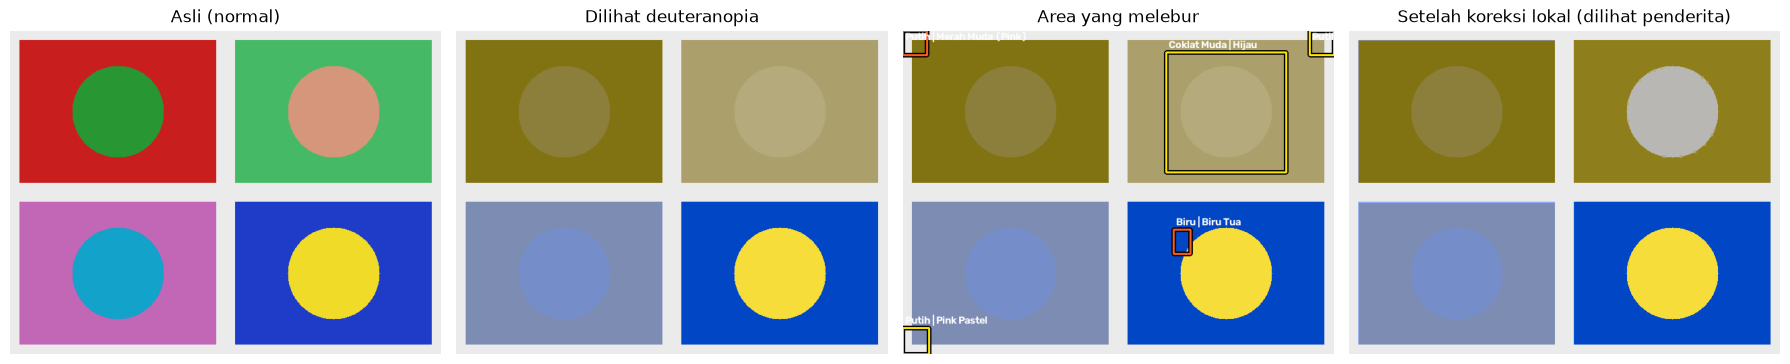

,Warna 1,Warna 2,dE normal,dE simulasi,dE setelah koreksi,Koreksi berhasil
0,Putih,Merah Muda (Pink),22.0,14.7,NaN,False
1,Putih,Hijau Muda,18.0,9.2,19.7,True
2,Coklat Muda,Hijau,41.0,3.8,28.1,True
3,Biru,Biru Tua,17.0,14.2,NaN,False
4,Putih,Pink Pastel,18.0,10.6,13.8,True


In [58]:
def peragakan_gambar(img_bgr, cvd="deuteranopia", gambar=True):
    """Satu gambar -> 4 panel: asli | simulasi penderita | solusi (kotak) | solusi (koreksi lokal, dilihat penderita)."""
    pelacak = PelacakPeleburan(min_umur=1)
    for _ in range(2):                                   
        tampil, dets, _ = proses_kamera_frame(img_bgr, cvd, True, pelacak)
    sim = simulasi_bgr(img_bgr, cvd)
    kotak = sim.copy()
    for d in dets:
        warna = (0, 230, 255) if d["ok"] else (31, 90, 255)
        x, y, w, h = (int(round(d[k])) for k in ("x", "y", "w", "h"))
        cv2.rectangle(kotak, (x, y), (x + w, y + h), (0, 0, 0), 5)
        cv2.rectangle(kotak, (x, y), (x + w, y + h), warna, 2)
        cv2.putText(kotak, f"{d['n1']} | {d['n2']}", (x + 4, max(14, y - 6)), FONT, 0.5, (255, 255, 255), 2, cv2.LINE_AA)
    if gambar:
        fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
        for a, im, t in zip(ax, [img_bgr, sim, kotak, tampil],
                            ["Asli (normal)", f"Dilihat {cvd}", "Area yang melebur", "Setelah koreksi lokal (dilihat penderita)"]):
            a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis("off")
        plt.tight_layout(); plt.show()
    tabel = pd.DataFrame([{"Warna 1": d["n1"], "Warna 2": d["n2"], "dE normal": d["de_n"], "dE simulasi": d["de_s"],
                           "dE setelah koreksi": d["de_k"], "Koreksi berhasil": d["ok"]} for d in dets])
    return tampil, dets, tabel


PASANGAN_UJI = {  
    "protanopia": [((253, 86, 32), (15, 137, 41)), ((2, 94, 111), (142, 67, 98)), ((29, 77, 20), (172, 36, 16)),
                   ((30, 60, 200), (240, 220, 40))],
    "deuteranopia": [((200, 30, 30), (40, 150, 50)), ((70, 185, 103), (214, 150, 123)), ((194, 102, 182), (18, 162, 202)),
                     ((30, 60, 200), (240, 220, 40))],
    "tritanopia": [((45, 180, 62), (118, 145, 218)), ((38, 190, 85), (106, 169, 208)), ((232, 113, 9), (245, 9, 242)),
                   ((200, 30, 30), (40, 150, 60))],
}


def _gambar_uji_peleburan(cvd="deuteranopia", w=640, h=480):
    """Gambar sintetis: 3 pasangan yang melebur untuk tipe `cvd` + 1 pasangan kontrol (tetap terbedakan)."""
    img = np.full((h, w, 3), 235, np.uint8)
    g = 14                                                   # jarak (abu-abu terang) antar panel
    for k, (bg, fg) in enumerate(PASANGAN_UJI[cvd]):
        r, c = divmod(k, 2)
        y0, x0 = r * (h // 2), c * (w // 2)
        img[y0 + g:y0 + h // 2 - g, x0 + g:x0 + w // 2 - g] = bg[::-1]
        cv2.circle(img, (x0 + w // 4, y0 + h // 4), h // 7, fg[::-1], -1)
    return img

_, _, tabel_uji = peragakan_gambar(_gambar_uji_peleburan("deuteranopia"), "deuteranopia")
tabel_uji

### 10.5 Eksekusi Kamera Asisten CVD *Real-Time* (`jalankan_kamera_cvd`)

Menjalankan aplikasi Kamera Asisten CVD secara *live* dengan pemrosesan berulir (*multi-threaded capture*), konversi ruang warna berbasis LUT, dan evaluasi deteksi perbatasan setiap `skip_deteksi = 2` *frame*[cite: 2].

**Kontrol Navigasi Interaktif (Klik Bar Atas Video atau Tekan Keyboard):**
* `1` / `2` / `3`: Mengubah profil simulasi ke **Protanopia** / **Deuteranopia** / **Tritanopia**[cite: 2].
* `S` / `Spasi`: Mengaktifkan atau menonaktifkan mode **Solusi** (penandaan kotak melebur & *daltonization* lokal)[cite: 2].
* `F` / `M`: Beralih antara **Mode Area** (pemindaian seluruh layar) dan **Mode Fokus Tengah** (satu kotak bidik di pusat layar)[cite: 2].
* `-` / `+`: Mengatur dimensi kotak bidik pada Mode Fokus Tengah (rentang $30\text{--}220\text{ px}$, interval $15\text{ px}$)[cite: 2].
* `N`: Beralih sementara ke tampilan penglihatan **Normal** (asli) sebagai pembanding[cite: 2].
* `Q` / `ESC`: Menghentikan kamera dan mencetak ringkasan *throughput* rata-rata (FPS)[cite: 2].

In [59]:
hasil_kamera = jalankan_kamera_cvd(mode_fokus="tengah", mode_awal="deuteranopia")

Kamera CVD Aktif! Navigasi: [1/2/3] Tipe CVD | [S] Solusi | [F] Mode Fokus Tengah/Area | [-/+] Ukuran Fokus | [N] Normal | [Q] Keluar
Selesai. 3863 frame, rata-rata olah 7.5 ms/frame, 59.9 FPS.
